🟢 Running locally
📁 Working directory: /Users/computer/dev/ai/pytorch
📁 Model path: forgery_detection_model.pth
📁 Output path: submission.csv

✅ Path configuration complete!

💡 Use these path variables in subsequent cells:
   TRAIN_IMAGES_DIR = train_images
   TRAIN_MASKS_DIR = train_masks
   TEST_IMAGES_DIR = test_images
   MODEL_PATH = forgery_detection_model.pth
   OUTPUT_PATH = submission.csv
Found 2751 mask files in train_masks/

Loading 20 examples...
[10/20] Loaded: 9, Failed: 0
[20/20] Loaded: 19, Failed: 0

Loaded: 20 | Failed: 0


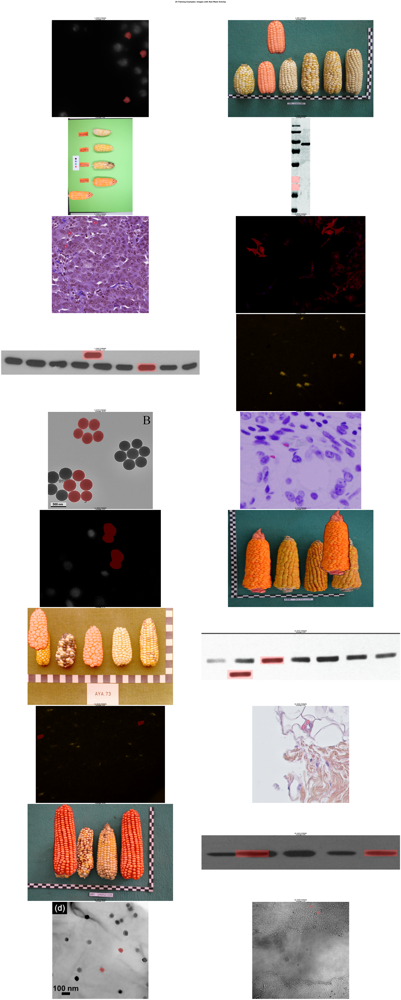


STATISTICS: 20 examples
Forged: 20 | Authentic: 0
Coverage - Min: 0.12%, Max: 20.58%, Mean: 5.40%
Creating U-Net with pre-trained ResNet34 encoder...
Model created! Total parameters: 23,613,313
Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 128, 128])

✅ Model ready for training!

💡 Alternative: You can also use 'segmentation_models_pytorch' library:
   pip install segmentation-models-pytorch
   from segmentation_models_pytorch import Unet
   model = Unet('resnet34', encoder_weights='imagenet', classes=1)
💡 To use this option, install: pip install segmentation-models-pytorch
   Then uncomment the code above!


In [1]:
import os
from pathlib import Path

# Detect if running on Kaggle
IS_KAGGLE = os.path.exists('/kaggle/input')
BEST_THRESHOLD = 0.5  # updated after validation threshold sweep

if IS_KAGGLE:
    print("🔵 Running on Kaggle Platform")
    print("="*60)
    
    # Kaggle paths - data is in /kaggle/input/recodai-luc-scientific-image-forgery-detection/
    KAGGLE_INPUT = Path('/kaggle/input')
    KAGGLE_WORKING = Path('/kaggle/working')
    COMPETITION_DATA = KAGGLE_INPUT / 'recodai-luc-scientific-image-forgery-detection'
    
    # Set up paths
    TRAIN_IMAGES_DIR = COMPETITION_DATA / 'train_images'
    TRAIN_MASKS_DIR = COMPETITION_DATA / 'train_masks'
    TEST_IMAGES_DIR = COMPETITION_DATA / 'test_images'
    SUPPLEMENTAL_IMAGES_DIR = COMPETITION_DATA / 'supplemental_images'
    SUPPLEMENTAL_MASKS_DIR = COMPETITION_DATA / 'supplemental_masks'
    MODEL_PATH = KAGGLE_WORKING / 'forgery_detection_model.pth'
    OUTPUT_PATH = KAGGLE_WORKING / 'submission.csv'
    
    print(f"📁 Competition data: {COMPETITION_DATA}")
    print(f"📁 Working directory: {KAGGLE_WORKING}")
    print(f"📁 Model path: {MODEL_PATH}")
    print(f"📁 Output path: {OUTPUT_PATH}")
    
    # Check if competition data exists
    if COMPETITION_DATA.exists():
        print(f"\n✅ Competition data found at: {COMPETITION_DATA}")
        for dir_name in ['train_images', 'train_masks', 'test_images', 'supplemental_images', 'supplemental_masks']:
            dir_path = COMPETITION_DATA / dir_name
            if dir_path.exists():
                file_count = len(list(dir_path.rglob('*.png'))) + len(list(dir_path.rglob('*.npy')))
                print(f"   {dir_name}/: {file_count} files")
    else:
        print(f"\n⚠️  Competition data not found at: {COMPETITION_DATA}")
        print("   Make sure to add the competition dataset to your notebook")
        print("   Click: + Add data → Search: recodai-luc-scientific-image-forgery-detection")
    
    # Check for model file (might be in input if uploaded as dataset)
    model_in_input = list(KAGGLE_INPUT.glob('**/forgery_detection_model.pth'))
    if model_in_input:
        MODEL_PATH = model_in_input[0]
        print(f"\n✅ Model found at: {MODEL_PATH}")
    elif MODEL_PATH.exists():
        print(f"\n✅ Model found at: {MODEL_PATH}")
    else:
        print(f"\n⚠️  Model not found. Will train new model or update MODEL_PATH")
    
else:
    print("🟢 Running locally")
    print("="*60)
    
    # Local paths (relative to notebook directory)
    TRAIN_IMAGES_DIR = Path('train_images')
    TRAIN_MASKS_DIR = Path('train_masks')
    TEST_IMAGES_DIR = Path('test_images')
    SUPPLEMENTAL_IMAGES_DIR = Path('supplemental_images')
    SUPPLEMENTAL_MASKS_DIR = Path('supplemental_masks')
    MODEL_PATH = Path('forgery_detection_model.pth')
    OUTPUT_PATH = Path('submission.csv')
    
    print(f"📁 Working directory: {Path.cwd()}")
    print(f"📁 Model path: {MODEL_PATH}")
    print(f"📁 Output path: {OUTPUT_PATH}")

print("\n" + "="*60)
print("✅ Path configuration complete!")
print("="*60)
print("\n💡 Use these path variables in subsequent cells:")
print(f"   TRAIN_IMAGES_DIR = {TRAIN_IMAGES_DIR}")
print(f"   TRAIN_MASKS_DIR = {TRAIN_MASKS_DIR}")
print(f"   TEST_IMAGES_DIR = {TEST_IMAGES_DIR}")
print(f"   MODEL_PATH = {MODEL_PATH}")
print(f"   OUTPUT_PATH = {OUTPUT_PATH}")


import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_device():
    """
    Get the best available device.
    Priority: MPS (Apple Silicon) > CUDA (NVIDIA) > CPU
    """
    if torch.backends.mps.is_available():
        return torch.device('mps')
    elif torch.cuda.is_available():
        return torch.device('cuda')
    else:
        return torch.device('cpu')

def get_device_name(device):
    """Get human-readable device name."""
    if device.type == 'mps':
        return 'Apple MPS (Metal)'
    elif device.type == 'cuda':
        return f'CUDA ({torch.cuda.get_device_name(0)})'
    else:
        return 'CPU'

def process_mask_to_2d(mask):
    """Convert mask of any shape to 2D array."""
    if len(mask.shape) == 3:
        if mask.shape[0] == 1:
            return mask[0]
        elif mask.shape[2] == 1:
            return mask[:, :, 0]
        else:
            return mask[0]
    elif len(mask.shape) == 2:
        return mask
    elif len(mask.shape) == 1:
        size = int(np.sqrt(mask.shape[0]))
        if size * size == mask.shape[0]:
            return mask.reshape(size, size)
    return None

def normalize_mask(mask_2d, target_shape):
    """Resize and normalize mask to match target image dimensions."""
    mask_height, mask_width = mask_2d.shape
    target_height, target_width = target_shape
    
    # Resize if needed
    if mask_height != target_height or mask_width != target_width:
        mask_uint8 = (mask_2d * 255).astype(np.uint8) if mask_2d.max() <= 1 else mask_2d.astype(np.uint8)
        mask_pil = Image.fromarray(mask_uint8)
        mask_resized = np.array(mask_pil.resize((target_width, target_height), Image.NEAREST))
    else:
        mask_resized = mask_2d.copy()
    
    # Normalize to 0-1 and binarize
    if mask_resized.max() > 1:
        mask_resized = mask_resized.astype(float) / 255.0
    else:
        mask_resized = mask_resized.astype(float)
    
    return (mask_resized > 0.5).astype(float)

def load_image_rgb(image_path):
    """Load image and convert to RGB format."""
    img_pil = Image.open(image_path)
    if img_pil.mode == 'RGBA':
        background = Image.new('RGB', img_pil.size, (255, 255, 255))
        background.paste(img_pil, mask=img_pil.split()[3])
        return np.array(background)
    return np.array(img_pil.convert('RGB'))

def ensure_rgb(image):
    """Ensure image is RGB (3 channels)."""
    if len(image.shape) == 2:
        return np.stack([image, image, image], axis=2)
    elif image.shape[2] == 4:
        return image[:, :, :3]
    elif image.shape[2] == 1:
        return np.repeat(image, 3, axis=2)
    return image

def create_red_overlay(image_float, mask_resized):
    """Create image with transparent red mask overlay."""
    red_overlay = np.zeros_like(image_float)
    red_overlay[:, :, 0] = mask_resized
    mask_3d = mask_resized[:, :, np.newaxis]
    overlay = image_float * (1 - mask_3d * 0.15) + red_overlay * 0.3
    return np.clip(overlay, 0, 1)

# ============================================================================
# MAIN CODE
# ============================================================================

# Setup paths (use auto-detected paths from Cell 1)
train_masks_dir = TRAIN_MASKS_DIR
train_images_forged_dir = TRAIN_IMAGES_DIR / 'forged'
train_images_authentic_dir = TRAIN_IMAGES_DIR / 'authentic'

# Get mask files
train_mask_files = list(train_masks_dir.glob('*.npy'))
print(f"Found {len(train_mask_files)} mask files in train_masks/")

# Configuration
num_examples = 20  # Set to None to load all examples

# Load examples
examples = []
failed = []

if train_mask_files:
    files_to_process = train_mask_files[:num_examples] if num_examples else train_mask_files
    print(f"\nLoading {len(files_to_process)} examples...")
    
    for i, mask_file in enumerate(files_to_process):
        mask_id = mask_file.stem
        
        # Progress update
        if (i + 1) % 10 == 0 or (i + 1) == len(files_to_process):
            print(f"[{i+1}/{len(files_to_process)}] Loaded: {len(examples)}, Failed: {len(failed)}")
        
        try:
            # Load mask
            mask = np.load(mask_file)
            
            # Find corresponding image
            forged_path = train_images_forged_dir / f"{mask_id}.png"
            authentic_path = train_images_authentic_dir / f"{mask_id}.png"
            
            image_path = forged_path if forged_path.exists() else (authentic_path if authentic_path.exists() else None)
            image_label = "forged" if forged_path.exists() else ("authentic" if authentic_path.exists() else None)
            
            if image_path is None:
                failed.append(f"{mask_id}: Image not found")
                continue
            
            # Load and process image
            try:
                image = load_image_rgb(image_path)
                target_shape = (image.shape[0], image.shape[1])
                
                # Process mask
                mask_2d = process_mask_to_2d(mask)
                if mask_2d is None or mask_2d.size == 0:
                    failed.append(f"{mask_id}: Invalid mask shape {mask.shape}")
                    continue
                
                # Ensure mask is 2D
                if len(mask_2d.shape) > 2:
                    mask_2d = mask_2d[:, :, 0] if mask_2d.shape[2] == 1 else mask_2d[:, :, 0]
                
                # Normalize mask to match image
                mask_resized = normalize_mask(mask_2d, target_shape)
                
                # Verify dimensions
                if mask_resized.shape == target_shape:
                    examples.append({
                        'mask_id': mask_id,
                        'image': image,
                        'mask': mask_resized,
                        'label': image_label
                    })
                else:
                    failed.append(f"{mask_id}: Dimension mismatch")
            except Exception as e:
                failed.append(f"{mask_id}: {str(e)}")
        except Exception as e:
            failed.append(f"{mask_id}: {str(e)}")
    
    # Print summary
    print(f"\n{'='*60}")
    print(f"Loaded: {len(examples)} | Failed: {len(failed)}")
    if failed and len(failed) <= 10:
        for f in failed:
            print(f"  - {f}")
    elif failed:
        for f in failed[:5]:
            print(f"  - {f}")
        print(f"  ... and {len(failed) - 5} more")
    print(f"{'='*60}")
    
    # Visualize examples
    if examples:
        n_examples = len(examples)
        cols = min(5, max(2, (n_examples + 9) // 10))  # 2-5 columns based on count
        rows = (n_examples + cols - 1) // cols
        
        fig = plt.figure(figsize=(18 * cols, 9 * rows))
        gs = fig.add_gridspec(rows, cols, hspace=0.01, wspace=0.01)
        plt.subplots_adjust(left=0.0, right=1.0, top=0.98, bottom=0.0, hspace=0.01, wspace=0.01)
        
        for idx, ex in enumerate(examples):
            row, col = idx // cols, idx % cols
            ax = fig.add_subplot(gs[row, col])
            
            try:
                image = ensure_rgb(ex['image'])
                mask = ex['mask']
                
                # Convert to float and create overlay
                image_float = (image.astype(np.float32) / 255.0) if image.dtype != np.float32 else image.copy()
                overlay = create_red_overlay(image_float, mask)
                
                ax.imshow(overlay)
                coverage = mask.sum() / mask.size * 100
                ax.set_title(f'{idx+1}: {ex["mask_id"]} ({ex["label"].upper()})\nCoverage: {coverage:.1f}%',
                            fontsize=7, fontweight='bold', pad=1)
            except Exception as e:
                ax.text(0.5, 0.5, f'Error\n{ex["mask_id"]}', ha='center', va='center',
                       fontsize=10, color='red')
                ax.set_title(f'Example {idx+1}: Error', fontsize=10)
            
            ax.axis('off')
        
        fig.suptitle(f'{n_examples} Training Examples: Images with Red Mask Overlay',
                    fontsize=11, fontweight='bold', y=0.999)
        plt.show()
        
        # Print statistics
        print(f"\n{'='*60}")
        print(f"STATISTICS: {len(examples)} examples")
        print(f"{'='*60}")
        forged_count = sum(1 for ex in examples if ex['label'] == 'forged')
        authentic_count = sum(1 for ex in examples if ex['label'] == 'authentic')
        print(f"Forged: {forged_count} | Authentic: {authentic_count}")
        
        coverages = [ex['mask'].sum() / ex['mask'].size * 100 for ex in examples]
        print(f"Coverage - Min: {min(coverages):.2f}%, Max: {max(coverages):.2f}%, Mean: {np.mean(coverages):.2f}%")
        print(f"{'='*60}")
    else:
        print("No examples loaded")
else:
    print("No mask files found in train_masks/")


# ============================================================================
# SEGMENTATION MODEL WITH PRE-TRAINED BACKBONE
# ============================================================================
# This cell shows how to use pre-trained models for segmentation
# Options: U-Net with ResNet/EfficientNet backbone, or use segmentation_models_pytorch

import torch
import torch.nn as nn
import torchvision.models as models
from torchvision.models import resnet34, ResNet34_Weights

# Option 1: Build U-Net with Pre-trained ResNet Encoder (Recommended)
# This is a simple implementation - you can also use segmentation_models_pytorch library

class UNetEncoder(nn.Module):
    """Encoder using pre-trained ResNet."""
    def __init__(self, pretrained=True):
        super().__init__()
        
        # Only load weights from Kaggle hardcoded path, no internet download
        if pretrained and IS_KAGGLE:
            kaggle_weights_path = Path('/kaggle/input/idk/pytorch/default/1/resnet34-b627a593.pth')
            if kaggle_weights_path.exists():
                print(f"✅ Loading ResNet34 weights from Kaggle dataset: {kaggle_weights_path}")
                resnet = resnet34(weights=None)  # Don't download
                resnet.load_state_dict(torch.load(kaggle_weights_path, map_location='cpu'))
            else:
                print(f"⚠️  Kaggle weights not found at {kaggle_weights_path}, using untrained weights")
                resnet = resnet34(weights=None)
        else:
            # Local or pretrained=False: use untrained weights (no download)
            resnet = resnet34(weights=None)
        
        # Extract encoder layers
        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool
        
        self.layer1 = resnet.layer1  # 64 channels
        self.layer2 = resnet.layer2  # 128 channels
        self.layer3 = resnet.layer3  # 256 channels
        self.layer4 = resnet.layer4  # 512 channels
        
    def forward(self, x):
        # Store skip connections
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        skip1 = x  # 64 channels
        x = self.maxpool(x)
        
        x = self.layer1(x)
        skip2 = x  # 64 channels
        x = self.layer2(x)
        skip3 = x  # 128 channels
        x = self.layer3(x)
        skip4 = x  # 256 channels
        x = self.layer4(x)  # 512 channels
        
        return x, skip1, skip2, skip3, skip4

class UNetDecoder(nn.Module):
    """Decoder for U-Net."""
    def __init__(self):
        super().__init__()
        # Upsampling layers - need to handle size mismatches with interpolation
        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv1 = nn.Sequential(
            nn.Conv2d(512, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )
        
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        
        self.up4 = nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2)
        self.conv4 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        
        # Final output layer
        self.final = nn.Conv2d(64, 1, 1)
        
    def forward(self, x, skip1, skip2, skip3, skip4):
        # Decoder with skip connections
        # x starts at 16x16 (after layer4)
        # skip4 is 32x32 (after layer3)
        # skip3 is 64x64 (after layer2)
        # skip2 is 128x128 (after layer1)
        # skip1 is 256x256 (before maxpool)
        
        # Up1: 16x16 -> 32x32, concat with skip4 (32x32)
        x = self.up1(x)
        if x.shape[2:] != skip4.shape[2:]:
            x = nn.functional.interpolate(x, size=skip4.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip4], dim=1)
        x = self.conv1(x)
        
        # Up2: 32x32 -> 64x64, concat with skip3 (64x64)
        x = self.up2(x)
        if x.shape[2:] != skip3.shape[2:]:
            x = nn.functional.interpolate(x, size=skip3.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip3], dim=1)
        x = self.conv2(x)
        
        # Up3: 64x64 -> 128x128, concat with skip2 (128x128)
        x = self.up3(x)
        if x.shape[2:] != skip2.shape[2:]:
            x = nn.functional.interpolate(x, size=skip2.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip2], dim=1)
        x = self.conv3(x)
        
        # Up4: 128x128 -> 256x256, concat with skip1 (256x256)
        x = self.up4(x)
        if x.shape[2:] != skip1.shape[2:]:
            x = nn.functional.interpolate(x, size=skip1.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip1], dim=1)
        x = self.conv4(x)
        
        x = self.final(x)
        return x

class UNetSegmentation(nn.Module):
    """Complete U-Net with pre-trained ResNet encoder."""
    def __init__(self, pretrained=True):
        super().__init__()
        self.encoder = UNetEncoder(pretrained=pretrained)
        self.decoder = UNetDecoder()
        
    def forward(self, x):
        x, skip1, skip2, skip3, skip4 = self.encoder(x)
        x = self.decoder(x, skip1, skip2, skip3, skip4)
        return torch.sigmoid(x)  # Output probabilities

# Create model
print("Creating U-Net with pre-trained ResNet34 encoder...")
model = UNetSegmentation(pretrained=True)
print(f"Model created! Total parameters: {sum(p.numel() for p in model.parameters()):,}")

# Test with dummy input
dummy_input = torch.randn(1, 3, 256, 256)
with torch.no_grad():
    output = model(dummy_input)
    print(f"Input shape: {dummy_input.shape}")
    print(f"Output shape: {output.shape}")  # Should be (1, 1, 256, 256)

print("\n✅ Model ready for training!")
print("\n💡 Alternative: You can also use 'segmentation_models_pytorch' library:")
print("   pip install segmentation-models-pytorch")
print("   from segmentation_models_pytorch import Unet")
print("   model = Unet('resnet34', encoder_weights='imagenet', classes=1)")


# ============================================================================
# EASIER OPTION: Use segmentation_models_pytorch Library
# ============================================================================
# This is the easiest way - just install and use!
# Uncomment the code below if you want to use this instead

# # Install the library (run this in a terminal or uncomment):
# # !pip install segmentation-models-pytorch

# try:
#     import segmentation_models_pytorch as smp
#     
#     # Create U-Net with pre-trained ResNet34 encoder
#     model = smp.Unet(
#         encoder_name="resnet34",        # Pre-trained encoder
#         encoder_weights="imagenet",     # Use ImageNet weights
#         in_channels=3,                  # RGB images
#         classes=1,                      # Binary segmentation (forgery mask)
#         activation=None,                # We'll apply sigmoid in loss
#     )
#     
#     print("✅ Model created using segmentation_models_pytorch!")
#     print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
#     
#     # Test
#     dummy_input = torch.randn(1, 3, 256, 256)
#     with torch.no_grad():
#         output = model(dummy_input)
#         print(f"Input: {dummy_input.shape} -> Output: {output.shape}")
#     
#     # Available encoders: resnet34, resnet50, efficientnet-b0, timm-efficientnet-b0, etc.
#     # Available models: Unet, FPN, Linknet, PSPNet, DeepLabV3, DeepLabV3Plus
#     
# except ImportError:
#     print("⚠️  segmentation_models_pytorch not installed.")
#     print("   Install with: pip install segmentation-models-pytorch")
#     print("   Or use the custom U-Net from the previous cell.")

print("💡 To use this option, install: pip install segmentation-models-pytorch")
print("   Then uncomment the code above!")


# ============================================================================
# MODEL READY FOR TRAINING
# ============================================================================
# Use Cell 1 for standard training on 500 images with proper train/val split
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import numpy as np
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# Helper functions (needed for this cell)
def process_mask_to_2d(mask):
    """Convert mask of any shape to 2D array."""
    if len(mask.shape) == 3:
        if mask.shape[0] == 1:
            return mask[0]
        elif mask.shape[2] == 1:
            return mask[:, :, 0]
        else:
            return mask[0]
    elif len(mask.shape) == 2:
        return mask
    elif len(mask.shape) == 1:
        size = int(np.sqrt(mask.shape[0]))
        if size * size == mask.shape[0]:
            return mask.reshape(size, size)
    return None

def normalize_mask(mask_2d, target_shape):
    """Resize and normalize mask to match target image dimensions."""
    mask_height, mask_width = mask_2d.shape
    target_height, target_width = target_shape
    
    # Resize if needed
    if mask_height != target_height or mask_width != target_width:
        mask_uint8 = (mask_2d * 255).astype(np.uint8) if mask_2d.max() <= 1 else mask_2d.astype(np.uint8)
        mask_pil = Image.fromarray(mask_uint8)
        mask_resized = np.array(mask_pil.resize((target_width, target_height), Image.NEAREST))
    else:
        mask_resized = mask_2d.copy()
    
    # Normalize to 0-1 and binarize
    if mask_resized.max() > 1:
        mask_resized = mask_resized.astype(float) / 255.0
    else:
        mask_resized = mask_resized.astype(float)
    
    return (mask_resized > 0.5).astype(float)

def load_image_rgb(image_path):
    """Load image and convert to RGB format."""
    img_pil = Image.open(image_path)
    if img_pil.mode == 'RGBA':
        background = Image.new('RGB', img_pil.size, (255, 255, 255))
        background.paste(img_pil, mask=img_pil.split()[3])
        return np.array(background)
    return np.array(img_pil.convert('RGB'))

# Overfit test code removed - use Cell 1 for standard 500 image training


TRAINING CONFIGURATION
Total images: 500
Train/Val split: 80% / 20%
Training images: 400
Validation images: 100
Max epochs: 10
Batch size: 8
Learning rate: 0.001

📁 Found 2751 mask files
📁 Using first 500 images

🔧 Creating dataset...
✅ Train dataset: 400 images
✅ Validation dataset: 100 images
✅ Train batches: 50
✅ Val batches: 13

🖥️  Using device: mps (Apple MPS (Metal))

🔄 Using existing model from memory...
   Total parameters: 23,613,313
   Trainable parameters: 23,613,313

STARTING TRAINING


Epoch 1/10 [Train]:   0%|          | 0/50 [00:00<?, ?it/s]/Users/computer/dev/ai/pytorch/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
Epoch 1/10 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.29it/s, loss=1.2119, iou=0.0000]



Epoch 1/10 Summary:
  Train Loss: 1.295447
  Val Loss:   1.183675
  Val IoU:    0.0144
  Val Dice:   0.0280
  LR:         0.001000
✅ Saved best model (val_loss: 1.183675)


Epoch 2/10 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.59it/s, loss=1.2494, iou=0.0000]



Epoch 2/10 Summary:
  Train Loss: 1.149618
  Val Loss:   1.352944
  Val IoU:    0.0079
  Val Dice:   0.0153
  LR:         0.001000


Epoch 3/10 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.64it/s, loss=1.1999, iou=0.0395]


... (11 outputs left out)

Epoch 9/10 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.58it/s, loss=1.4038, iou=0.0404]



Epoch 9/10 Summary:
  Train Loss: 1.042231
  Val Loss:   1.129009
  Val IoU:    0.1506
  Val Dice:   0.2549
  LR:         0.000500


Epoch 10/10 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.57it/s, loss=0.9878, iou=0.1315]



Epoch 10/10 Summary:
  Train Loss: 1.047704
  Val Loss:   1.008489
  Val IoU:    0.1572
  Val Dice:   0.2671
  LR:         0.000500
✅ Saved best model (val_loss: 1.008489)

TRAINING COMPLETE
Best validation loss: 1.008489
Final validation IoU: 0.1572
Final validation Dice: 0.2671
Model saved to: forgery_detection_model.pth


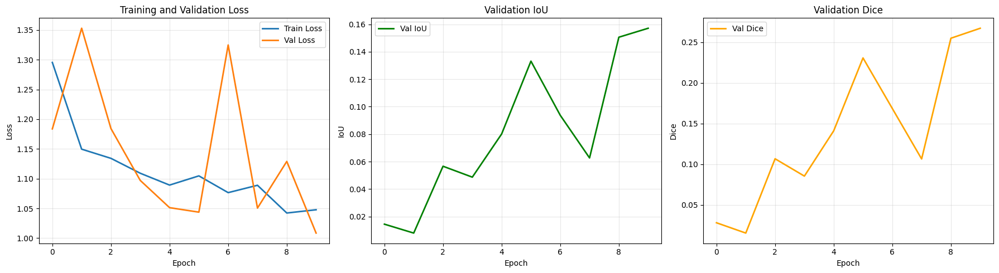


✅ Training visualization complete!
💡 Model is ready for testing and visualization


In [4]:
# ============================================================================
# STANDARD TRAINING: 500 Images, 10 Epochs Max, Proper Train/Val Split
# ============================================================================
# Standard training configuration:
# - 500 images total (400 training, 100 validation)
# - Max 10 epochs with early stopping
# - Proper train/validation split (validation data is NOT used in training)
# - Data augmentation on training set only
# - Uses Apple MPS / CUDA / CPU automatically

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image
import numpy as np
from tqdm import tqdm
from pathlib import Path
import cv2  # For CLAHE contrast normalization

# ============================================================================
# STANDARD CONFIGURATION (500 images)
# ============================================================================
NUM_TRAIN_IMAGES = 500  # Standard: 500 images total
MAX_EPOCHS = 10  # Max epochs (early stopping may stop earlier)
BATCH_SIZE = 8
LEARNING_RATE = 0.001
TARGET_SIZE = 256
VAL_SPLIT = 0.2  # 20% for validation (100 images), 80% for training (400 images)

print("="*60)
print("TRAINING CONFIGURATION")
print("="*60)
print(f"Total images: {NUM_TRAIN_IMAGES}")
print(f"Train/Val split: {1-VAL_SPLIT:.0%} / {VAL_SPLIT:.0%}")
print(f"Training images: {int(NUM_TRAIN_IMAGES * (1-VAL_SPLIT))}")
print(f"Validation images: {int(NUM_TRAIN_IMAGES * VAL_SPLIT)}")
print(f"Max epochs: {MAX_EPOCHS}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Learning rate: {LEARNING_RATE}")
print("="*60)

# Dataset class
class ForgeryDataset(Dataset):
    def __init__(self, mask_files, image_dir_forged, image_dir_authentic, target_size=256, transform=None):
        self.mask_files = mask_files
        self.image_dir_forged = image_dir_forged
        self.image_dir_authentic = image_dir_authentic
        self.target_size = target_size
        self.transform = transform
        
    def __len__(self):
        return len(self.mask_files)
    
    def __getitem__(self, idx):
        mask_file = self.mask_files[idx]
        mask_id = mask_file.stem
        
        # Load mask
        mask = np.load(mask_file)
        mask_2d = process_mask_to_2d(mask)
        if mask_2d is None:
            mask_2d = np.zeros((256, 256), dtype=np.float32)
        
        # Load image
        forged_path = self.image_dir_forged / f"{mask_id}.png"
        authentic_path = self.image_dir_authentic / f"{mask_id}.png"
        image_path = forged_path if forged_path.exists() else authentic_path
        
        if not image_path.exists():
            # Return dummy data if image not found
            image = np.zeros((256, 256, 3), dtype=np.uint8)
            image_pil = Image.fromarray(image)
        else:
            # Load RGB image (keep colors - model can use color information)
            image_pil = Image.open(image_path).convert('RGB')
            # Convert to numpy for CLAHE processing
            image_np = np.array(image_pil)
            
            # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
            # This normalizes brightness/contrast differences between different image types
            # (e.g., dark microscopic images vs bright normal photos)
            if len(image_np.shape) == 3:
                # Convert RGB to LAB color space for better contrast normalization
                lab = cv2.cvtColor(image_np, cv2.COLOR_RGB2LAB)
                l_channel, a_channel, b_channel = cv2.split(lab)
                
                # Apply CLAHE to L channel (lightness) only
                clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
                l_channel_clahe = clahe.apply(l_channel)
                
                # Merge channels back and convert to RGB
                lab_clahe = cv2.merge([l_channel_clahe, a_channel, b_channel])
                image_np = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
            
            # Convert back to PIL
            image_pil = Image.fromarray(image_np)
        
        # Resize to target size
        mask_pil = Image.fromarray((mask_2d * 255).astype(np.uint8))
        
        image_resized = image_pil.resize((self.target_size, self.target_size), Image.BILINEAR)
        mask_resized = mask_pil.resize((self.target_size, self.target_size), Image.NEAREST)
        
        # Convert to tensors
        image_tensor = transforms.ToTensor()(image_resized)  # (3, H, W) - grayscale in RGB format
        mask_tensor = transforms.ToTensor()(mask_resized)  # (1, H, W)
        mask_tensor = (mask_tensor > 0.5).float()  # Binarize
        
        # Apply transforms if provided (for data augmentation on training set)
        if self.transform:
            # Convert back to PIL for transforms
            image_pil = transforms.ToPILImage()(image_tensor)
            image_pil = self.transform(image_pil)
            image_tensor = transforms.ToTensor()(image_pil)
        
        return image_tensor, mask_tensor

# Loss function
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCELoss()
    
    def forward(self, pred, target):
        # Dice coefficient
        smooth = 1.0
        pred_flat = pred.view(-1)
        target_flat = target.view(-1)
        intersection = (pred_flat * target_flat).sum()
        dice = (2.0 * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)
        dice_loss = 1 - dice
        
        # Combined loss
        bce_loss = self.bce(pred, target)
        return bce_loss + dice_loss

# Load mask files
train_mask_files = list(TRAIN_MASKS_DIR.glob('*.npy'))
print(f"\n📁 Found {len(train_mask_files)} mask files")

# Limit to NUM_TRAIN_IMAGES
if len(train_mask_files) > NUM_TRAIN_IMAGES:
    train_mask_files = train_mask_files[:NUM_TRAIN_IMAGES]
    print(f"📁 Using first {NUM_TRAIN_IMAGES} images")

# Create dataset
print("\n🔧 Creating dataset...")
dataset = ForgeryDataset(
    mask_files=train_mask_files,
    image_dir_forged=TRAIN_IMAGES_DIR / 'forged',
    image_dir_authentic=TRAIN_IMAGES_DIR / 'authentic',
    target_size=TARGET_SIZE,
    transform=None  # Will add augmentation for training set
)

# Split into train and validation (ensuring no overlap)
train_size = int(len(dataset) * (1 - VAL_SPLIT))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Add data augmentation to training set only
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
])

# Create augmented training dataset
class AugmentedDataset(Dataset):
    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform
    
    def __len__(self):
        return len(self.base_dataset)
    
    def __getitem__(self, idx):
        image, mask = self.base_dataset[idx]
        if self.transform:
            # Convert tensor back to PIL for transforms (already grayscale in RGB format)
            image_pil = transforms.ToPILImage()(image)
            image_pil = self.transform(image_pil)
            image = transforms.ToTensor()(image_pil)
        return image, mask

train_dataset_augmented = AugmentedDataset(train_dataset, train_transform)

# Create data loaders
train_loader = DataLoader(
    train_dataset_augmented,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print(f"✅ Train dataset: {len(train_dataset)} images")
print(f"✅ Validation dataset: {len(val_dataset)} images")
print(f"✅ Train batches: {len(train_loader)}")
print(f"✅ Val batches: {len(val_loader)}")

# Get device
device = get_device()
device_name = get_device_name(device)
print(f"\n🖥️  Using device: {device} ({device_name})")

# Create or load model
if 'model' not in globals():
    print("\n🏗️  Creating new model...")
    model = UNetSegmentation(pretrained=True).to(device)
else:
    print("\n🔄 Using existing model from memory...")
    model = model.to(device)

print(f"   Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# Loss, optimizer, scheduler
criterion = DiceBCELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# Training history
history = {
    'train_loss': [],
    'val_loss': [],
    'val_iou': [],
    'val_dice': [],
}

best_val_loss = float('inf')
patience_counter = 0
early_stop_patience = 5

print("\n" + "="*60)
print("STARTING TRAINING")
print("="*60)

for epoch in range(MAX_EPOCHS):
    # Training phase
    model.train()
    train_losses = []
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{MAX_EPOCHS} [Train]")
    for images, masks in pbar:
        images = images.to(device)
        masks = masks.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        
        # Resize output if needed
        if outputs.shape[2:] != masks.shape[2:]:
            outputs = nn.functional.interpolate(
                outputs, size=masks.shape[2:],
                mode='bilinear', align_corners=False
            )
        
        loss = criterion(outputs, masks)
        loss.backward()
        
        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        train_losses.append(loss.item())
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = np.mean(train_losses)
    
    # Validation phase
    model.eval()
    val_losses = []
    val_ious = []
    val_dices = []
    
    with torch.no_grad():
        pbar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{MAX_EPOCHS} [Val]")
        for images, masks in pbar:
            images = images.to(device)
            masks = masks.to(device)
            
            outputs = model(images)
            
            # Resize output if needed
            if outputs.shape[2:] != masks.shape[2:]:
                outputs = nn.functional.interpolate(
                    outputs, size=masks.shape[2:],
                    mode='bilinear', align_corners=False
                )
            
            loss = criterion(outputs, masks)
            val_losses.append(loss.item())
            
            # Calculate metrics
            pred_binary = (outputs > 0.5).float()
            target_binary = masks
            
            # IoU
            intersection = (pred_binary * target_binary).sum()
            union = (pred_binary + target_binary > 0).sum()
            iou = (intersection / (union + 1e-8)).item()
            val_ious.append(iou)
            
            # Dice
            dice = (2 * intersection / (pred_binary.sum() + target_binary.sum() + 1e-8)).item()
            val_dices.append(dice)
            
            pbar.set_postfix({'loss': f'{loss.item():.4f}', 'iou': f'{iou:.4f}'})
    
    avg_val_loss = np.mean(val_losses)
    avg_val_iou = np.mean(val_ious)
    avg_val_dice = np.mean(val_dices)
    
    # Update learning rate
    scheduler.step(avg_val_loss)
    
    # Save history
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_iou'].append(avg_val_iou)
    history['val_dice'].append(avg_val_dice)
    
    # Print epoch summary
    print(f"\n{'='*60}")
    print(f"Epoch {epoch+1}/{MAX_EPOCHS} Summary:")
    print(f"  Train Loss: {avg_train_loss:.6f}")
    print(f"  Val Loss:   {avg_val_loss:.6f}")
    print(f"  Val IoU:    {avg_val_iou:.4f}")
    print(f"  Val Dice:   {avg_val_dice:.4f}")
    print(f"  LR:         {optimizer.param_groups[0]['lr']:.6f}")
    print("="*60)
    
    # Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
        # Save model
        torch.save(model.state_dict(), MODEL_PATH)
        print(f"✅ Saved best model (val_loss: {best_val_loss:.6f})")
    else:
        patience_counter += 1
        if patience_counter >= early_stop_patience:
            print(f"\n⏹️  Early stopping triggered (no improvement for {early_stop_patience} epochs)")
            break

print("\n" + "="*60)
print("TRAINING COMPLETE")
print("="*60)
print(f"Best validation loss: {best_val_loss:.6f}")
print(f"Final validation IoU: {history['val_iou'][-1]:.4f}")
print(f"Final validation Dice: {history['val_dice'][-1]:.4f}")
print(f"Model saved to: {MODEL_PATH}")

# Plot training history
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(history['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# IoU
axes[1].plot(history['val_iou'], label='Val IoU', linewidth=2, color='green')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('IoU')
axes[1].set_title('Validation IoU')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Dice
axes[2].plot(history['val_dice'], label='Val Dice', linewidth=2, color='orange')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Dice')
axes[2].set_title('Validation Dice')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✅ Training visualization complete!")
print("💡 Model is ready for testing and visualization")

VISUALIZING U-NET INTERNAL ACTIVATIONS FOR 5 IMAGES
Using device: mps (Apple MPS (Metal))
Loading image 1/5: 48280
Loading image 2/5: 8081
Loading image 3/5: 10799
Loading image 4/5: 20882
Loading image 5/5: 36986

✅ Loaded 5 images

Generating visualization...


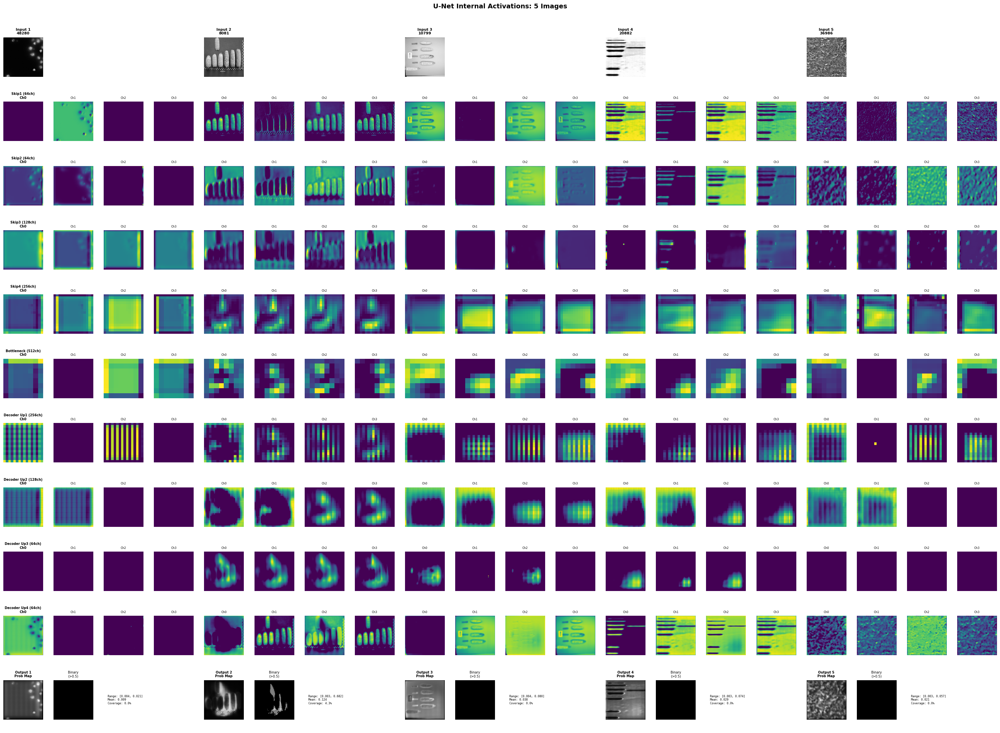


✅ Visualization complete!

💡 What to look for:
   - Each column shows one image
   - Each row shows a different layer
   - Compare how different images activate the same layers
   - Final outputs show if model is learning to detect forgery regions


In [5]:
# ============================================================================
# VISUALIZE U-NET INTERNAL ACTIVATIONS
# ============================================================================
# This cell visualizes what happens inside the U-Net model at each layer
# Shows encoder features, skip connections, decoder features, and final output

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image

def visualize_unet_internals(model, image_tensor, device, save_path=None):
    """
    Visualize intermediate activations in U-Net model.
    
    Args:
        model: UNetSegmentation model
        image_tensor: Input image tensor (1, 3, H, W)
        device: torch device
        save_path: Optional path to save figure
    """
    model.eval()
    
    # Storage for activations
    activations = {}
    
    # Hook functions to capture activations
    def get_activation(name):
        def hook(model, input, output):
            activations[name] = output.detach()
        return hook
    
    # Register hooks for encoder layers
    hooks = []
    hooks.append(model.encoder.conv1.register_forward_hook(get_activation('encoder_conv1')))
    hooks.append(model.encoder.layer1.register_forward_hook(get_activation('encoder_layer1')))
    hooks.append(model.encoder.layer2.register_forward_hook(get_activation('encoder_layer2')))
    hooks.append(model.encoder.layer3.register_forward_hook(get_activation('encoder_layer3')))
    hooks.append(model.encoder.layer4.register_forward_hook(get_activation('encoder_layer4')))
    
    # Register hooks for decoder layers
    hooks.append(model.decoder.conv1.register_forward_hook(get_activation('decoder_conv1')))
    hooks.append(model.decoder.conv2.register_forward_hook(get_activation('decoder_conv2')))
    hooks.append(model.decoder.conv3.register_forward_hook(get_activation('decoder_conv3')))
    hooks.append(model.decoder.conv4.register_forward_hook(get_activation('decoder_conv4')))
    hooks.append(model.decoder.final.register_forward_hook(get_activation('decoder_final')))
    
    # Forward pass
    with torch.no_grad():
        image_tensor = image_tensor.to(device)
        
        # Manually go through encoder to capture skip connections
        x = image_tensor
        x = model.encoder.conv1(x)
        x = model.encoder.bn1(x)
        x = model.encoder.relu(x)
        skip1 = x  # 64 channels, 256x256
        activations['skip1'] = skip1
        
        x = model.encoder.maxpool(x)
        x = model.encoder.layer1(x)
        skip2 = x  # 64 channels, 128x128
        activations['skip2'] = skip2
        
        x = model.encoder.layer2(x)
        skip3 = x  # 128 channels, 64x64
        activations['skip3'] = skip3
        
        x = model.encoder.layer3(x)
        skip4 = x  # 256 channels, 32x32
        activations['skip4'] = skip4
        
        x = model.encoder.layer4(x)  # 512 channels, 16x16
        activations['bottleneck'] = x
        
        # Now go through decoder
        x = model.decoder.up1(x)
        if x.shape[2:] != skip4.shape[2:]:
            x = nn.functional.interpolate(x, size=skip4.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip4], dim=1)
        x = model.decoder.conv1(x)
        activations['decoder_up1'] = x
        
        x = model.decoder.up2(x)
        if x.shape[2:] != skip3.shape[2:]:
            x = nn.functional.interpolate(x, size=skip3.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip3], dim=1)
        x = model.decoder.conv2(x)
        activations['decoder_up2'] = x
        
        x = model.decoder.up3(x)
        if x.shape[2:] != skip2.shape[2:]:
            x = nn.functional.interpolate(x, size=skip2.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip2], dim=1)
        x = model.decoder.conv3(x)
        activations['decoder_up3'] = x
        
        x = model.decoder.up4(x)
        if x.shape[2:] != skip1.shape[2:]:
            x = nn.functional.interpolate(x, size=skip1.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip1], dim=1)
        x = model.decoder.conv4(x)
        activations['decoder_up4'] = x
        
        x = model.decoder.final(x)
        output = torch.sigmoid(x)
        activations['output'] = output
    
    # Remove hooks
    for hook in hooks:
        hook.remove()
    
    # Visualization - Use a 10x8 grid (80 subplots) to fit everything
    fig = plt.figure(figsize=(20, 20))
    cols = 8
    rows = 10
    
    # Helper function to visualize feature maps
    def visualize_features(features, title, row, start_col, num_channels=8):
        """Visualize first N channels of feature maps."""
        if features is None:
            return
        feat = features[0].cpu().numpy()  # Remove batch dimension
        num_channels = min(num_channels, feat.shape[0])
        
        for i in range(num_channels):
            pos = row * cols + start_col + i + 1
            if pos > rows * cols:
                return  # Skip if out of bounds
            ax = fig.add_subplot(rows, cols, pos)
            channel = feat[i]
            # Normalize for visualization
            channel = (channel - channel.min()) / (channel.max() - channel.min() + 1e-8)
            ax.imshow(channel, cmap='viridis')
            ax.set_title(f'{title}\nCh{i}', fontsize=7)
            ax.axis('off')
    
    # Row 0: Input image (span 2 columns)
    ax = fig.add_subplot(rows, cols, 1)
    img = image_tensor[0].cpu().permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min())
    ax.imshow(img)
    ax.set_title('INPUT IMAGE', fontsize=10, fontweight='bold')
    ax.axis('off')
    
    # Row 0: Final outputs (span 2 columns each)
    output_img = activations['output'][0, 0].cpu().numpy()
    binary_output = (output_img > 0.5).astype(float)
    
    ax = fig.add_subplot(rows, cols, 3)
    ax.imshow(output_img, cmap='gray')
    ax.set_title('FINAL OUTPUT\n(Probability)', fontsize=9, fontweight='bold')
    ax.axis('off')
    
    ax = fig.add_subplot(rows, cols, 4)
    ax.imshow(binary_output, cmap='gray')
    ax.set_title('BINARY OUTPUT\n(Threshold 0.5)', fontsize=9, fontweight='bold')
    ax.axis('off')
    
    # Statistics (span 4 columns)
    ax = fig.add_subplot(rows, cols, 5)
    ax.axis('off')
    stats_text = f"""STATISTICS:

Input: {image_tensor.shape}
Output: {activations['output'].shape}

Range: [{output_img.min():.3f}, {output_img.max():.3f}]
Mean: {output_img.mean():.3f}
Std: {output_img.std():.3f}

Forgery Pixels: {binary_output.sum():.0f} / {binary_output.size}
Coverage: {binary_output.sum() / binary_output.size * 100:.2f}%"""
    ax.text(0.05, 0.5, stats_text, fontsize=8, verticalalignment='center',
            family='monospace', transform=ax.transAxes)
    
    # Row 1: Encoder - Skip1 (8 channels)
    visualize_features(activations.get('skip1'), 'Skip1\n(64ch)', 1, 0, 8)
    
    # Row 2: Encoder - Skip2 (8 channels)
    visualize_features(activations.get('skip2'), 'Skip2\n(64ch)', 2, 0, 8)
    
    # Row 3: Encoder - Skip3 (8 channels)
    visualize_features(activations.get('skip3'), 'Skip3\n(128ch)', 3, 0, 8)
    
    # Row 4: Encoder - Skip4 (8 channels)
    visualize_features(activations.get('skip4'), 'Skip4\n(256ch)', 4, 0, 8)
    
    # Row 5: Encoder - Bottleneck (8 channels)
    visualize_features(activations.get('bottleneck'), 'Bottleneck\n(512ch)', 5, 0, 8)
    
    # Row 6: Decoder - Up1 (8 channels)
    visualize_features(activations.get('decoder_up1'), 'Decoder Up1\n(256ch)', 6, 0, 8)
    
    # Row 7: Decoder - Up2 (8 channels)
    visualize_features(activations.get('decoder_up2'), 'Decoder Up2\n(128ch)', 7, 0, 8)
    
    # Row 8: Decoder - Up3 (8 channels)
    visualize_features(activations.get('decoder_up3'), 'Decoder Up3\n(64ch)', 8, 0, 8)
    
    # Row 9: Decoder - Up4 (8 channels)
    visualize_features(activations.get('decoder_up4'), 'Decoder Up4\n(64ch)', 9, 0, 8)
    
    plt.suptitle('U-Net Internal Activations Visualization', fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✅ Saved visualization to: {save_path}")
    
    plt.show()
    
    return activations

def visualize_multiple_images_internals(model, image_tensors, image_ids, device, save_path=None):
    """
    Visualize intermediate activations for multiple images in a single plot.
    
    Args:
        model: UNetSegmentation model
        image_tensors: List of image tensors, each (1, 3, H, W)
        image_ids: List of image IDs for labeling
        device: torch device
        save_path: Optional path to save figure
    """
    model.eval()
    num_images = len(image_tensors)
    
    # Process all images and collect activations
    all_activations = []
    
    for img_idx, image_tensor in enumerate(image_tensors):
        activations = {}
        
        # Hook functions to capture activations
        def get_activation(name, idx):
            def hook(model, input, output):
                if name not in activations:
                    activations[name] = []
                activations[name].append(output.detach())
            return hook
        
        # Register hooks
        hooks = []
        hooks.append(model.encoder.conv1.register_forward_hook(get_activation('encoder_conv1', img_idx)))
        hooks.append(model.encoder.layer1.register_forward_hook(get_activation('encoder_layer1', img_idx)))
        hooks.append(model.encoder.layer2.register_forward_hook(get_activation('encoder_layer2', img_idx)))
        hooks.append(model.encoder.layer3.register_forward_hook(get_activation('encoder_layer3', img_idx)))
        hooks.append(model.encoder.layer4.register_forward_hook(get_activation('encoder_layer4', img_idx)))
        
        # Forward pass
        with torch.no_grad():
            image_tensor = image_tensor.to(device)
            
            # Manually go through encoder to capture skip connections
            x = image_tensor
            x = model.encoder.conv1(x)
            x = model.encoder.bn1(x)
            x = model.encoder.relu(x)
            skip1 = x
            activations['skip1'] = [skip1]
            
            x = model.encoder.maxpool(x)
            x = model.encoder.layer1(x)
            skip2 = x
            activations['skip2'] = [skip2]
            
            x = model.encoder.layer2(x)
            skip3 = x
            activations['skip3'] = [skip3]
            
            x = model.encoder.layer3(x)
            skip4 = x
            activations['skip4'] = [skip4]
            
            x = model.encoder.layer4(x)
            activations['bottleneck'] = [x]
            
            # Decoder
            x = model.decoder.up1(x)
            if x.shape[2:] != skip4.shape[2:]:
                x = nn.functional.interpolate(x, size=skip4.shape[2:], mode='bilinear', align_corners=False)
            x = torch.cat([x, skip4], dim=1)
            x = model.decoder.conv1(x)
            activations['decoder_up1'] = [x]
            
            x = model.decoder.up2(x)
            if x.shape[2:] != skip3.shape[2:]:
                x = nn.functional.interpolate(x, size=skip3.shape[2:], mode='bilinear', align_corners=False)
            x = torch.cat([x, skip3], dim=1)
            x = model.decoder.conv2(x)
            activations['decoder_up2'] = [x]
            
            x = model.decoder.up3(x)
            if x.shape[2:] != skip2.shape[2:]:
                x = nn.functional.interpolate(x, size=skip2.shape[2:], mode='bilinear', align_corners=False)
            x = torch.cat([x, skip2], dim=1)
            x = model.decoder.conv3(x)
            activations['decoder_up3'] = [x]
            
            x = model.decoder.up4(x)
            if x.shape[2:] != skip1.shape[2:]:
                x = nn.functional.interpolate(x, size=skip1.shape[2:], mode='bilinear', align_corners=False)
            x = torch.cat([x, skip1], dim=1)
            x = model.decoder.conv4(x)
            activations['decoder_up4'] = [x]
            
            x = model.decoder.final(x)
            output = torch.sigmoid(x)
            activations['output'] = [output]
        
        # Remove hooks
        for hook in hooks:
            hook.remove()
        
        all_activations.append(activations)
    
    # Create visualization - organized by layer, showing all images side by side
    # Layout: Each row is a layer, columns are images (5 images)
    # For each layer, show 4 channels per image
    layers = [
        ('skip1', 'Skip1 (64ch)', 1),
        ('skip2', 'Skip2 (64ch)', 2),
        ('skip3', 'Skip3 (128ch)', 3),
        ('skip4', 'Skip4 (256ch)', 4),
        ('bottleneck', 'Bottleneck (512ch)', 5),
        ('decoder_up1', 'Decoder Up1 (256ch)', 6),
        ('decoder_up2', 'Decoder Up2 (128ch)', 7),
        ('decoder_up3', 'Decoder Up3 (64ch)', 8),
        ('decoder_up4', 'Decoder Up4 (64ch)', 9),
    ]
    
    channels_per_image = 4
    rows = len(layers) + 2  # +2 for input images and outputs
    cols = num_images * channels_per_image
    
    fig = plt.figure(figsize=(cols * 1.5, rows * 2))
    
    # Row 0: Input images
    for img_idx in range(num_images):
        for ch_idx in range(channels_per_image):
            ax = fig.add_subplot(rows, cols, img_idx * channels_per_image + ch_idx + 1)
            if ch_idx == 0:
                img = image_tensors[img_idx][0].cpu().permute(1, 2, 0).numpy()
                img = (img - img.min()) / (img.max() - img.min())
                ax.imshow(img)
                ax.set_title(f'Input {img_idx+1}\n{image_ids[img_idx]}', fontsize=8, fontweight='bold')
            else:
                ax.axis('off')
            ax.axis('off')
    
    # Rows 1-9: Layer activations
    for layer_idx, (layer_name, layer_title, row) in enumerate(layers):
        for img_idx in range(num_images):
            activations = all_activations[img_idx]
            if layer_name in activations and activations[layer_name]:
                feat = activations[layer_name][0][0].cpu().numpy()  # Remove batch dimension
                num_channels = min(channels_per_image, feat.shape[0])
                
                for ch_idx in range(channels_per_image):
                    pos = row * cols + img_idx * channels_per_image + ch_idx + 1
                    ax = fig.add_subplot(rows, cols, pos)
                    
                    if ch_idx < num_channels:
                        channel = feat[ch_idx]
                        channel = (channel - channel.min()) / (channel.max() - channel.min() + 1e-8)
                        ax.imshow(channel, cmap='viridis')
                        if img_idx == 0 and ch_idx == 0:
                            ax.set_title(f'{layer_title}\nCh{ch_idx}', fontsize=7, fontweight='bold')
                        else:
                            ax.set_title(f'Ch{ch_idx}', fontsize=6)
                    else:
                        ax.axis('off')
                    ax.axis('off')
    
    # Last row: Final outputs
    output_row = rows - 1
    for img_idx in range(num_images):
        activations = all_activations[img_idx]
        if 'output' in activations and activations['output']:
            output_img = activations['output'][0][0, 0].cpu().numpy()
            binary_output = (output_img > 0.5).astype(float)
            
            # Probability map
            ax = fig.add_subplot(rows, cols, output_row * cols + img_idx * channels_per_image + 1)
            ax.imshow(output_img, cmap='gray')
            ax.set_title(f'Output {img_idx+1}\nProb Map', fontsize=7, fontweight='bold')
            ax.axis('off')
            
            # Binary output
            ax = fig.add_subplot(rows, cols, output_row * cols + img_idx * channels_per_image + 2)
            ax.imshow(binary_output, cmap='gray')
            ax.set_title(f'Binary\n(>0.5)', fontsize=7)
            ax.axis('off')
            
            # Statistics
            ax = fig.add_subplot(rows, cols, output_row * cols + img_idx * channels_per_image + 3)
            ax.axis('off')
            stats_text = f"""Range: [{output_img.min():.3f}, {output_img.max():.3f}]
Mean: {output_img.mean():.3f}
Coverage: {binary_output.sum() / binary_output.size * 100:.1f}%"""
            ax.text(0.1, 0.5, stats_text, fontsize=6, verticalalignment='center',
                   family='monospace', transform=ax.transAxes)
            
            # Empty space
            ax = fig.add_subplot(rows, cols, output_row * cols + img_idx * channels_per_image + 4)
            ax.axis('off')
    
    plt.suptitle(f'U-Net Internal Activations: {num_images} Images', fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✅ Saved visualization to: {save_path}")
    
    plt.show()
    
    return all_activations

# Test visualization with 5 images
print("="*60)
print("VISUALIZING U-NET INTERNAL ACTIVATIONS FOR 5 IMAGES")
print("="*60)

# Load 5 sample images
train_masks_dir = TRAIN_MASKS_DIR
train_images_forged_dir = TRAIN_IMAGES_DIR / 'forged'
train_images_authentic_dir = TRAIN_IMAGES_DIR / 'authentic'

train_mask_files = list(train_masks_dir.glob('*.npy'))
if train_mask_files:
    # Get device
    device = get_device()
    device_name = get_device_name(device)
    print(f"Using device: {device} ({device_name})")
    
    # Make sure model exists
    if 'model' not in globals():
        print("⚠️  Model not found in memory. Creating new model...")
        model = UNetSegmentation(pretrained=True).to(device)
    else:
        model = model.to(device)
    
    # Load 5 images
    image_tensors = []
    image_ids = []
    
    for i in range(min(5, len(train_mask_files))):
        mask_file = train_mask_files[i]
        mask_id = mask_file.stem
        
        # Find corresponding image
        forged_path = train_images_forged_dir / f"{mask_id}.png"
        authentic_path = train_images_authentic_dir / f"{mask_id}.png"
        image_path = forged_path if forged_path.exists() else authentic_path
        
        if image_path and image_path.exists():
            print(f"Loading image {i+1}/5: {mask_id}")
            
            # Load and preprocess image
            # Convert to grayscale first (removes color noise)
            image = Image.open(image_path).convert('L')  # 'L' = grayscale
            # Convert back to RGB by duplicating (model expects 3 channels)
            image = image.convert('RGB')
            image_resized = image.resize((256, 256), Image.BILINEAR)
            image_tensor = transforms.ToTensor()(image_resized).unsqueeze(0)  # (1, 3, 256, 256) - grayscale in RGB format
            
            image_tensors.append(image_tensor)
            image_ids.append(mask_id)
        else:
            print(f"⚠️  Image not found: {mask_id}")
    
    if len(image_tensors) == 5:
        print(f"\n✅ Loaded {len(image_tensors)} images")
        print("\nGenerating visualization...")
        all_activations = visualize_multiple_images_internals(model, image_tensors, image_ids, device)
        
        print("\n✅ Visualization complete!")
        print("\n💡 What to look for:")
        print("   - Each column shows one image")
        print("   - Each row shows a different layer")
        print("   - Compare how different images activate the same layers")
        print("   - Final outputs show if model is learning to detect forgery regions")
    else:
        print(f"❌ Could only load {len(image_tensors)} images, need 5")
else:
    print("❌ No mask files found!")


TESTING ON UNSEEN IMAGE
Using device: mps (Apple MPS (Metal))
✅ Using model from memory

📁 Using training image with ground truth: train_images/forged/11307.png
📁 Ground truth mask: train_masks/11307.npy
   Image ID: 11307

Testing on: 11307.png

Loading test image: train_images/forged/11307.png
Loading ground truth mask: train_masks/11307.npy
Running inference and capturing activations...

ACCURACY METRICS
Pixel Accuracy: 0.9942 (99.42%)
IoU (Intersection over Union): 0.0000
Dice Coefficient: 0.0000
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000
Predicted Forgery Pixels: 0
True Forgery Pixels: 382
Intersection: 0
Union: 382


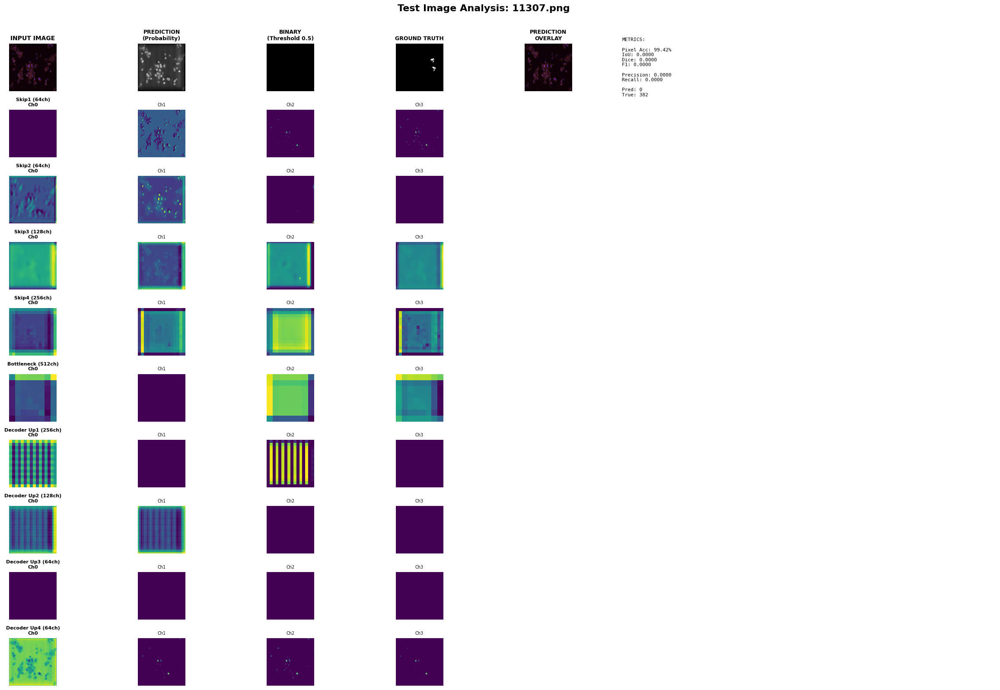


✅ Test complete!


In [6]:
# ============================================================================
# TEST ON UNSEEN IMAGE: Accuracy Metrics + Internal Activations
# ============================================================================
# Test the model on an image it hasn't seen before
# Calculate accuracy metrics and visualize internal activations

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image
from pathlib import Path
import json
import cv2  # For CLAHE contrast normalization

def calculate_metrics(pred_mask, true_mask, threshold=0.5):
    """
    Calculate accuracy metrics for segmentation.
    
    Returns:
        dict with accuracy, IoU, Dice, precision, recall, F1
    """
    # Ensure shapes match - resize pred_mask to match true_mask before binarization
    if pred_mask.shape != true_mask.shape:
        # Resize pred_mask to match true_mask size (preserve continuous values)
        pred_mask_uint8 = (np.clip(pred_mask, 0, 1) * 255).astype(np.uint8)
        pred_mask_pil = Image.fromarray(pred_mask_uint8)
        true_h, true_w = true_mask.shape
        pred_mask_resized = np.array(pred_mask_pil.resize((true_w, true_h), Image.BILINEAR)).astype(float) / 255.0
        pred_mask = pred_mask_resized
    
    # Binarize predictions
    pred_binary = (pred_mask > threshold).astype(float)
    true_binary = (true_mask > 0.5).astype(float)
    
    # Calculate metrics
    intersection = (pred_binary * true_binary).sum()
    union = (pred_binary + true_binary > 0).sum()
    pred_sum = pred_binary.sum()
    true_sum = true_binary.sum()
    
    # Pixel accuracy
    pixel_acc = (pred_binary == true_binary).sum() / pred_binary.size
    
    # IoU (Intersection over Union)
    iou = intersection / (union + 1e-8)
    
    # Dice coefficient
    dice = (2 * intersection) / (pred_sum + true_sum + 1e-8)
    
    # Precision, Recall, F1
    precision = intersection / (pred_sum + 1e-8)
    recall = intersection / (true_sum + 1e-8)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-8)
    
    return {
        'pixel_accuracy': float(pixel_acc),
        'iou': float(iou),
        'dice': float(dice),
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1),
        'predicted_pixels': int(pred_sum),
        'true_pixels': int(true_sum),
        'intersection': int(intersection),
        'union': int(union)
    }

def test_and_visualize(model, image_path, mask_path=None, device='cpu', threshold=0.5):
    """
    Test model on an image and visualize internal activations.
    
    Args:
        model: Trained model
        image_path: Path to test image
        mask_path: Optional path to ground truth mask
        device: torch device
        threshold: Threshold for binary prediction
    """
    model.eval()
    
    # Load and preprocess image
    print(f"Loading test image: {image_path}")
    # Load RGB image
    image = Image.open(image_path).convert('RGB')
    original_size = image.size  # (width, height)
    
    # Apply CLAHE for contrast normalization
    image_np = np.array(image)
    if len(image_np.shape) == 3:
        lab = cv2.cvtColor(image_np, cv2.COLOR_RGB2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l_channel_clahe = clahe.apply(l_channel)
        lab_clahe = cv2.merge([l_channel_clahe, a_channel, b_channel])
        image_np = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
        image = Image.fromarray(image_np)
    
    image_resized = image.resize((256, 256), Image.BILINEAR)
    image_tensor = transforms.ToTensor()(image_resized).unsqueeze(0).to(device)  # (1, 3, 256, 256) - RGB with CLAHE
    
    # Load ground truth mask if available
    true_mask = None
    if mask_path and Path(mask_path).exists():
        print(f"Loading ground truth mask: {mask_path}")
        mask = np.load(mask_path)
        mask_2d = process_mask_to_2d(mask)
        if mask_2d is not None:
            # Resize to match model output size
            mask_uint8 = (mask_2d * 255).astype(np.uint8) if mask_2d.max() <= 1 else mask_2d.astype(np.uint8)
            mask_pil = Image.fromarray(mask_uint8)
            true_mask = np.array(mask_pil.resize((256, 256), Image.NEAREST)).astype(float) / 255.0
    
    # Run inference and capture activations
    print("Running inference and capturing activations...")
    activations = {}
    
    def get_activation(name):
        def hook(model, input, output):
            activations[name] = output.detach()
        return hook
    
    hooks = []
    hooks.append(model.encoder.conv1.register_forward_hook(get_activation('encoder_conv1')))
    hooks.append(model.encoder.layer1.register_forward_hook(get_activation('encoder_layer1')))
    hooks.append(model.encoder.layer2.register_forward_hook(get_activation('encoder_layer2')))
    hooks.append(model.encoder.layer3.register_forward_hook(get_activation('encoder_layer3')))
    hooks.append(model.encoder.layer4.register_forward_hook(get_activation('encoder_layer4')))
    
    with torch.no_grad():
        # Forward pass through encoder
        x = image_tensor
        x = model.encoder.conv1(x)
        x = model.encoder.bn1(x)
        x = model.encoder.relu(x)
        skip1 = x
        activations['skip1'] = skip1
        
        x = model.encoder.maxpool(x)
        x = model.encoder.layer1(x)
        skip2 = x
        activations['skip2'] = skip2
        
        x = model.encoder.layer2(x)
        skip3 = x
        activations['skip3'] = skip3
        
        x = model.encoder.layer3(x)
        skip4 = x
        activations['skip4'] = skip4
        
        x = model.encoder.layer4(x)
        activations['bottleneck'] = x
        
        # Decoder
        x = model.decoder.up1(x)
        if x.shape[2:] != skip4.shape[2:]:
            x = nn.functional.interpolate(x, size=skip4.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip4], dim=1)
        x = model.decoder.conv1(x)
        activations['decoder_up1'] = x
        
        x = model.decoder.up2(x)
        if x.shape[2:] != skip3.shape[2:]:
            x = nn.functional.interpolate(x, size=skip3.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip3], dim=1)
        x = model.decoder.conv2(x)
        activations['decoder_up2'] = x
        
        x = model.decoder.up3(x)
        if x.shape[2:] != skip2.shape[2:]:
            x = nn.functional.interpolate(x, size=skip2.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip2], dim=1)
        x = model.decoder.conv3(x)
        activations['decoder_up3'] = x
        
        x = model.decoder.up4(x)
        if x.shape[2:] != skip1.shape[2:]:
            x = nn.functional.interpolate(x, size=skip1.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip1], dim=1)
        x = model.decoder.conv4(x)
        activations['decoder_up4'] = x
        
        x = model.decoder.final(x)
        output = torch.sigmoid(x)
        activations['output'] = output
    
    # Remove hooks
    for hook in hooks:
        hook.remove()
    
    # Get prediction
    pred_mask = output[0, 0].cpu().numpy()  # (256, 256)
    pred_binary = (pred_mask > threshold).astype(float)
    
    # Calculate metrics if ground truth available
    metrics = None
    if true_mask is not None:
        metrics = calculate_metrics(pred_mask, true_mask, threshold)
        print("\n" + "="*60)
        print("ACCURACY METRICS")
        print("="*60)
        print(f"Pixel Accuracy: {metrics['pixel_accuracy']:.4f} ({metrics['pixel_accuracy']*100:.2f}%)")
        print(f"IoU (Intersection over Union): {metrics['iou']:.4f}")
        print(f"Dice Coefficient: {metrics['dice']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}")
        print(f"Recall: {metrics['recall']:.4f}")
        print(f"F1 Score: {metrics['f1']:.4f}")
        print(f"Predicted Forgery Pixels: {metrics['predicted_pixels']}")
        print(f"True Forgery Pixels: {metrics['true_pixels']}")
        print(f"Intersection: {metrics['intersection']}")
        print(f"Union: {metrics['union']}")
        print("="*60)
    else:
        print("\n⚠️  No ground truth mask available - showing predictions only")
        print(f"Predicted Forgery Pixels: {pred_binary.sum():.0f} / {pred_binary.size}")
        print(f"Coverage: {pred_binary.sum() / pred_binary.size * 100:.2f}%")
    
    # Create comprehensive visualization
    fig = plt.figure(figsize=(24, 16))
    
    # Helper function to visualize features
    def visualize_features(features, title, row, start_col, num_channels=4):
        if features is None:
            return
        feat = features[0].cpu().numpy()
        num_channels = min(num_channels, feat.shape[0])
        
        for i in range(num_channels):
            ax = fig.add_subplot(10, 8, row * 8 + start_col + i + 1)
            channel = feat[i]
            channel = (channel - channel.min()) / (channel.max() - channel.min() + 1e-8)
            ax.imshow(channel, cmap='viridis')
            if i == 0:
                ax.set_title(f'{title}\nCh{i}', fontsize=8, fontweight='bold')
            else:
                ax.set_title(f'Ch{i}', fontsize=7)
            ax.axis('off')
    
    # Row 0: Input image and outputs
    ax = fig.add_subplot(10, 8, 1)
    img = image_tensor[0].cpu().permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min())
    ax.imshow(img)
    ax.set_title('INPUT IMAGE', fontsize=10, fontweight='bold')
    ax.axis('off')
    
    # Probability map
    ax = fig.add_subplot(10, 8, 2)
    ax.imshow(pred_mask, cmap='gray')
    ax.set_title('PREDICTION\n(Probability)', fontsize=9, fontweight='bold')
    ax.axis('off')
    
    # Binary prediction
    ax = fig.add_subplot(10, 8, 3)
    ax.imshow(pred_binary, cmap='gray')
    ax.set_title('BINARY\n(Threshold 0.5)', fontsize=9, fontweight='bold')
    ax.axis('off')
    
    # Ground truth (if available)
    ax = fig.add_subplot(10, 8, 4)
    if true_mask is not None:
        ax.imshow(true_mask, cmap='gray')
        ax.set_title('GROUND TRUTH', fontsize=9, fontweight='bold')
    else:
        ax.text(0.5, 0.5, 'No\nGround Truth', ha='center', va='center', fontsize=10)
        ax.set_title('GROUND TRUTH', fontsize=9)
    ax.axis('off')
    
    # Overlay visualization
    ax = fig.add_subplot(10, 8, 5)
    overlay = img.copy()
    
    # Ensure pred_binary matches img size
    img_h, img_w = img.shape[:2]
    if pred_binary.shape != (img_h, img_w):
        # Resize pred_binary to match img using PIL
        pred_binary_uint8 = (pred_binary * 255).astype(np.uint8)
        pred_binary_pil = Image.fromarray(pred_binary_uint8)
        pred_binary_resized = np.array(pred_binary_pil.resize((img_w, img_h), Image.NEAREST)).astype(float) / 255.0
        pred_binary_resized = (pred_binary_resized > 0.5).astype(float)
    else:
        pred_binary_resized = pred_binary
    
    red_mask = np.zeros_like(overlay)
    red_mask[:, :, 0] = pred_binary_resized
    mask_3d = pred_binary_resized[:, :, np.newaxis]
    overlay_result = overlay * (1 - mask_3d * 0.3) + red_mask * 0.5
    ax.imshow(np.clip(overlay_result, 0, 1))
    ax.set_title('PREDICTION\nOVERLAY', fontsize=9, fontweight='bold')
    ax.axis('off')
    
    # Metrics text
    ax = fig.add_subplot(10, 8, 6)
    ax.axis('off')
    if metrics:
        metrics_text = f"""METRICS:
        
Pixel Acc: {metrics['pixel_accuracy']*100:.2f}%
IoU: {metrics['iou']:.4f}
Dice: {metrics['dice']:.4f}
F1: {metrics['f1']:.4f}

Precision: {metrics['precision']:.4f}
Recall: {metrics['recall']:.4f}

Pred: {metrics['predicted_pixels']}
True: {metrics['true_pixels']}"""
    else:
        metrics_text = f"""PREDICTION STATS:

Range: [{pred_mask.min():.3f}, {pred_mask.max():.3f}]
Mean: {pred_mask.mean():.3f}
Std: {pred_mask.std():.3f}

Predicted Pixels: {pred_binary.sum():.0f}
Coverage: {pred_binary.sum() / pred_binary.size * 100:.2f}%"""
    ax.text(0.05, 0.5, metrics_text, fontsize=8, verticalalignment='center',
           family='monospace', transform=ax.transAxes)
    
    # Empty spaces
    for i in range(7, 9):
        ax = fig.add_subplot(10, 8, i)
        ax.axis('off')
    
    # Rows 1-9: Layer activations
    visualize_features(activations.get('skip1'), 'Skip1 (64ch)', 1, 0, 4)
    visualize_features(activations.get('skip2'), 'Skip2 (64ch)', 2, 0, 4)
    visualize_features(activations.get('skip3'), 'Skip3 (128ch)', 3, 0, 4)
    visualize_features(activations.get('skip4'), 'Skip4 (256ch)', 4, 0, 4)
    visualize_features(activations.get('bottleneck'), 'Bottleneck (512ch)', 5, 0, 4)
    visualize_features(activations.get('decoder_up1'), 'Decoder Up1 (256ch)', 6, 0, 4)
    visualize_features(activations.get('decoder_up2'), 'Decoder Up2 (128ch)', 7, 0, 4)
    visualize_features(activations.get('decoder_up3'), 'Decoder Up3 (64ch)', 8, 0, 4)
    visualize_features(activations.get('decoder_up4'), 'Decoder Up4 (64ch)', 9, 0, 4)
    
    plt.suptitle(f'Test Image Analysis: {Path(image_path).name}', fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    return pred_mask, pred_binary, metrics, activations

# ============================================================================
# RUN TEST
# ============================================================================

print("="*60)
print("TESTING ON UNSEEN IMAGE")
print("="*60)

# Get device
device = get_device()
device_name = get_device_name(device)
print(f"Using device: {device} ({device_name})")

# Make sure model exists
if 'model' not in globals():
    print("⚠️  Model not found in memory. Loading from disk...")
    if MODEL_PATH.exists():
        model = UNetSegmentation(pretrained=False).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()
        print(f"✅ Model loaded from: {MODEL_PATH}")
    else:
        print(f"❌ Model not found at: {MODEL_PATH}")
        print("   Please train the model first or update MODEL_PATH")
        raise FileNotFoundError(f"Model not found: {MODEL_PATH}")
else:
    model = model.to(device)
    print("✅ Using model from memory")

# Try to find a training image with ground truth mask (for validation)
test_image_path = None
test_mask_path = None

# Option 1: Use a training image with ground truth mask (PRIORITY - for validation)
train_mask_files = list(TRAIN_MASKS_DIR.glob('*.npy'))
if train_mask_files:
    # Use a later image (less likely to be in training set, but still has ground truth)
    test_mask_file = train_mask_files[-20]  # Use 10th from end
    mask_id = test_mask_file.stem
    test_mask_path = test_mask_file
    
    # Find corresponding image
    forged_path = TRAIN_IMAGES_DIR / 'forged' / f"{mask_id}.png"
    authentic_path = TRAIN_IMAGES_DIR / 'authentic' / f"{mask_id}.png"
    test_image_path = forged_path if forged_path.exists() else authentic_path
    
    if test_image_path and test_image_path.exists():
        print(f"\n📁 Using training image with ground truth: {test_image_path}")
        print(f"📁 Ground truth mask: {test_mask_path}")
        print(f"   Image ID: {mask_id}")

# Option 2: Fallback to test_images directory (no ground truth)
if test_image_path is None or not test_image_path.exists():
    if TEST_IMAGES_DIR.exists():
        test_images = list(TEST_IMAGES_DIR.glob('*.png'))
        if test_images:
            test_image_path = test_images[0]
            test_mask_path = None  # No ground truth for test images
            print(f"\n📁 Using test image (no ground truth): {test_image_path}")
            print("   ⚠️  No ground truth mask available - metrics will not be calculated")

if test_image_path and test_image_path.exists():
    print(f"\n{'='*60}")
    print(f"Testing on: {Path(test_image_path).name}")
    print(f"{'='*60}\n")
    
    # Run test
    pred_mask, pred_binary, metrics, activations = test_and_visualize(
        model, 
        test_image_path, 
        mask_path=test_mask_path,
        device=device,
        threshold=0.5
    )
    
    print("\n✅ Test complete!")
else:
    print("\n❌ No test image found!")
    print("   Please ensure test_images/ directory exists or training data is available")

THRESHOLD ANALYSIS
Using device: mps (Apple MPS (Metal))
✅ Using model from memory
📁 Found list with 50 files, processing ALL images

Processing image 1/50: 34597
📁 Test image: train_images/forged/34597.png
📁 Ground truth mask: train_masks/34597.npy
🔮 Running inference...
✅ Prediction complete!
   Probability range: [0.003, 0.836]
   Mean probability: 0.411
🏆 Best-F1(threshold sweep): 0.4 (F1=0.2291, IoU=0.1294) | AUTO(Otsu+fallback): 0.391 (F1=0.2290, IoU=0.1293)

Processing image 2/50: 23772
📁 Test image: train_images/forged/23772.png
📁 Ground truth mask: train_masks/23772.npy
🔮 Running inference...
✅ Prediction complete!
   Probability range: [0.003, 0.773]
   Mean probability: 0.150
🏆 Best-F1(threshold sweep): 0.4 (F1=0.4370, IoU=0.2796) | AUTO(Otsu+fallback): 0.328 (F1=0.4261, IoU=0.2707)

Processing image 3/50: 47586
📁 Test image: train_images/forged/47586.png
📁 Ground truth mask: train_masks/47586.npy
🔮 Running inference...
✅ Prediction complete!
   Probability range: [0.004, 0.

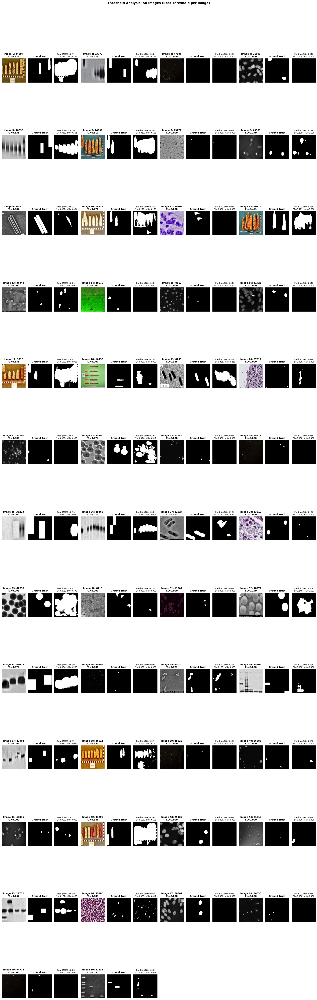

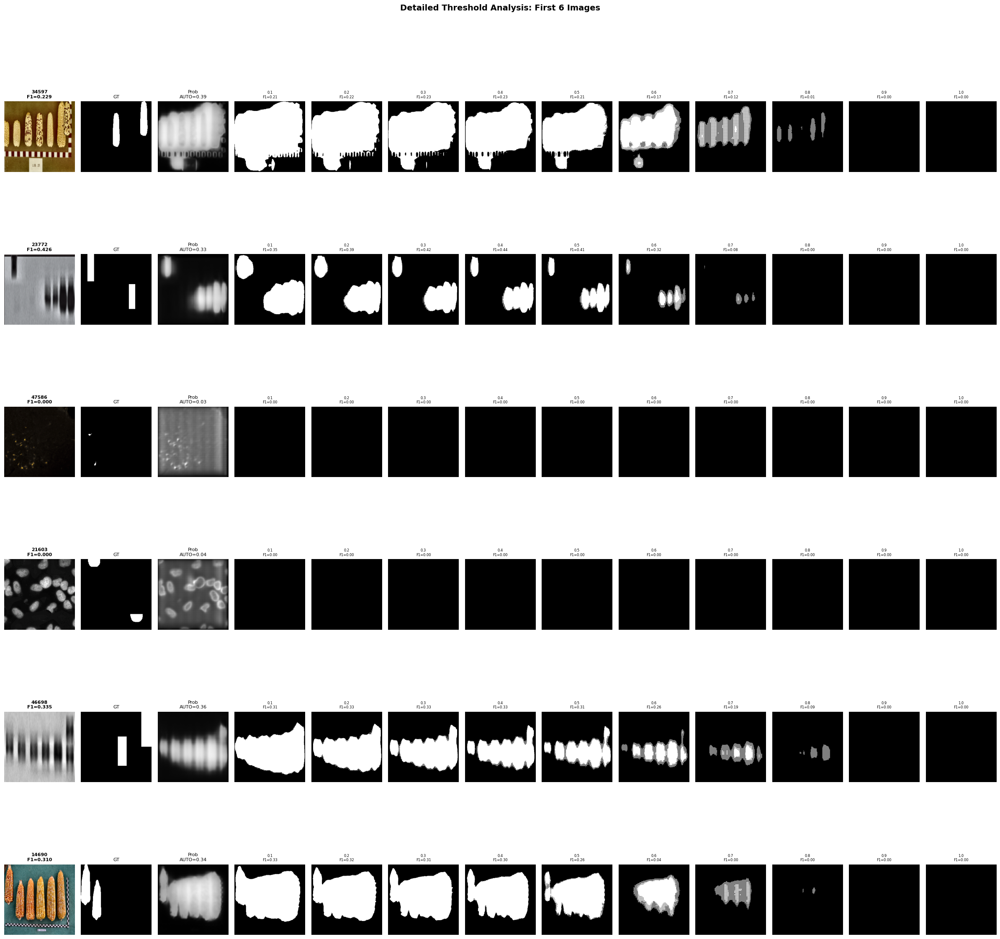

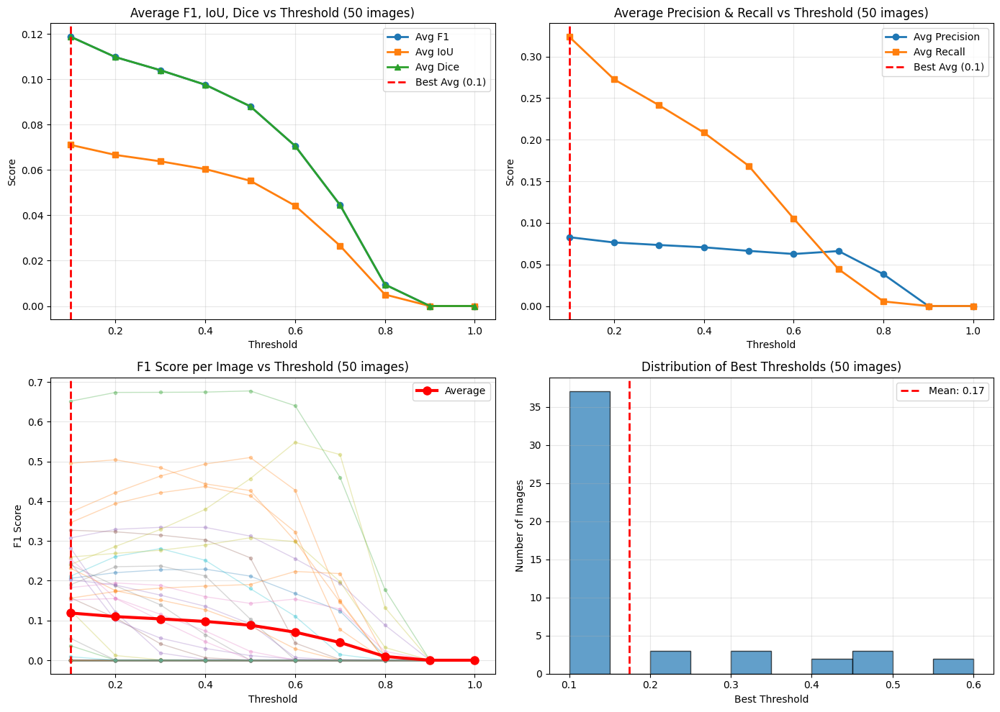


SUMMARY: 50 Images Processed
Best average threshold: 0.1 (Avg F1=0.1187)
Individual best thresholds: ['0.4', '0.4', '0.1', '0.1', '0.3', '0.1', '0.1', '0.1', '0.1', '0.3', '0.1', '0.2', '0.1', '0.1', '0.1', '0.1', '0.2', '0.1', '0.6', '0.1', '0.1', '0.5', '0.1', '0.1', '0.1', '0.1', '0.1', '0.1', '0.5', '0.1', '0.1', '0.1', '0.5', '0.1', '0.1', '0.1', '0.2', '0.3', '0.1', '0.1', '0.1', '0.6', '0.1', '0.1', '0.1', '0.1', '0.1', '0.1', '0.1', '0.1']
Mean best threshold: 0.17

✅ Threshold analysis complete!
💡 Recommended threshold: 0.1 (based on average F1 across 50 images)


In [12]:
# ============================================================================
# THRESHOLD ANALYSIS: Test Different Probability Thresholds
# ============================================================================
# Test prediction probabilities with thresholds from 0.1 to 1.0 (0.1 increments)
# Uses the 20th image from the end (validation image)

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image
from pathlib import Path
import cv2  # For CLAHE contrast normalization

# ----------------------------
# Auto-threshold helpers
# ----------------------------

def otsu_threshold(prob_map_0_1: np.ndarray) -> float:
    """Otsu threshold on a probability map in [0, 1]. Returns threshold in [0, 1]."""
    p = np.clip(prob_map_0_1, 0.0, 1.0)
    p_u8 = (p * 255.0).astype(np.uint8)
    # cv2.threshold returns (threshold_value, thresholded_image)
    t_u8, _ = cv2.threshold(p_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return float(t_u8) / 255.0


def percentile_threshold(prob_map_0_1: np.ndarray, q: float = 99.0) -> float:
    """Pick threshold as q-th percentile of probabilities (keeps only the brightest tail)."""
    p = np.clip(prob_map_0_1, 0.0, 1.0)
    return float(np.percentile(p, q))


# You can tune these two knobs to "raise the bar" (keep only the brightest tail)
AUTO_TAIL_PERCENTILE = 99.5  # try 99.5, 99.5, 99.9
AUTO_BIAS = 0.03  # adds a small upward push; try 0.00, 0.02, 0.05


def auto_threshold(prob_map_0_1: np.ndarray, *, tail_q: float = AUTO_TAIL_PERCENTILE, bias: float = AUTO_BIAS) -> float:
    """Auto threshold: Otsu, with (tail percentile + bias) fallback. Returns threshold in [0.01, 0.99]."""
    p = np.clip(prob_map_0_1, 0.0, 1.0)
    t = otsu_threshold(p)

    # If Otsu is degenerate, or you want a higher "tail cut", use percentile+ bias
    if t <= 1e-3 or t >= 0.999:
        t = percentile_threshold(p, q=float(tail_q))

    # Always apply the bias to raise/lower the cut a bit
    t = float(t) + float(bias)

    # Keep in a sane range
    return float(np.clip(t, 0.01, 0.99))


print("="*60)
print("THRESHOLD ANALYSIS")
print("="*60)

# Get device
device = get_device()
device_name = get_device_name(device)
print(f"Using device: {device} ({device_name})")

# Make sure model exists
if 'model' not in globals():
    print("⚠️  Model not found in memory. Loading from disk...")
    if MODEL_PATH.exists():
        model = UNetSegmentation(pretrained=False).to(device)
        model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
        model.eval()
        print(f"✅ Model loaded from: {MODEL_PATH}")
    else:
        print(f"❌ Model not found at: {MODEL_PATH}")
        print("   Please train the model first (Cell 1)")
        raise FileNotFoundError(f"Model not found: {MODEL_PATH}")
else:
    model = model.to(device)
    model.eval()
    print("✅ Using model from memory")

# Load test image (20th from end)
train_mask_files = list(TRAIN_MASKS_DIR.glob('*.npy'))
if not train_mask_files:
    print("❌ No mask files found!")
else:
    # Handle both single file and list of files
    # Can use: train_mask_files[-20] for single file
    # Or: train_mask_files[-52:-40] for list of files (will process ALL files)
    # test_mask_file = train_mask_files[-20]  # Default: single file (20th from end)
    test_mask_file = train_mask_files[-50:]  # List of files
    
    # Check if it's a list or single file
    if isinstance(test_mask_file, list):
        test_mask_files = test_mask_file
        print(f"📁 Found list with {len(test_mask_files)} files, processing ALL images")
    else:
        test_mask_files = [test_mask_file]  # Convert single file to list
        print(f"📁 Processing single image")
    
    if len(test_mask_files) == 0:
        print("❌ No valid test mask files!")
    else:
        # Process all images
        all_results = []
        
        for img_idx, test_mask_file in enumerate(test_mask_files):
            mask_id = test_mask_file.stem
            test_mask_path = test_mask_file
            
            # Find corresponding image
            forged_path = TRAIN_IMAGES_DIR / 'forged' / f"{mask_id}.png"
            authentic_path = TRAIN_IMAGES_DIR / 'authentic' / f"{mask_id}.png"
            test_image_path = forged_path if forged_path.exists() else authentic_path
            
            if test_image_path and test_image_path.exists():
                print(f"\n{'='*60}")
                print(f"Processing image {img_idx+1}/{len(test_mask_files)}: {mask_id}")
                print(f"📁 Test image: {test_image_path}")
                print(f"📁 Ground truth mask: {test_mask_path}")
                
                # Load and preprocess image
                # Load RGB image
                image = Image.open(test_image_path).convert('RGB')
                original_size = image.size
                
                # Apply CLAHE for contrast normalization
                image_np = np.array(image)
                if len(image_np.shape) == 3:
                    lab = cv2.cvtColor(image_np, cv2.COLOR_RGB2LAB)
                    l_channel, a_channel, b_channel = cv2.split(lab)
                    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
                    l_channel_clahe = clahe.apply(l_channel)
                    lab_clahe = cv2.merge([l_channel_clahe, a_channel, b_channel])
                    image_np = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
                    image = Image.fromarray(image_np)
                
                image_resized = image.resize((256, 256), Image.BILINEAR)
                image_tensor = transforms.ToTensor()(image_resized).unsqueeze(0).to(device)  # RGB with CLAHE
        
                # Load ground truth mask
                mask = np.load(test_mask_path)
                mask_2d = process_mask_to_2d(mask)
                if mask_2d is not None:
                    mask_uint8 = (mask_2d * 255).astype(np.uint8) if mask_2d.max() <= 1 else mask_2d.astype(np.uint8)
                    mask_pil = Image.fromarray(mask_uint8)
                    true_mask = np.array(mask_pil.resize((256, 256), Image.NEAREST)).astype(float) / 255.0
                else:
                    true_mask = np.zeros((256, 256), dtype=float)
                
                # Get prediction
                print("🔮 Running inference...")
                with torch.no_grad():
                    output = model(image_tensor)
                    # Resize if needed
                    if output.shape[2:] != (256, 256):
                        output = nn.functional.interpolate(
                            output, size=(256, 256),
                            mode='bilinear', align_corners=False
                        )
                    pred_prob = output[0, 0].cpu().numpy()  # (256, 256) probability map
                
                print(f"✅ Prediction complete!")
                print(f"   Probability range: [{pred_prob.min():.3f}, {pred_prob.max():.3f}]")
                print(f"   Mean probability: {pred_prob.mean():.3f}")
                
                # Test different thresholds
                thresholds = np.arange(0.1, 1.1, 0.1)  # [0.1, 0.2, ..., 1.0]
                
                # Calculate metrics for each threshold
                threshold_results = []
                for threshold in thresholds:
                    pred_binary = (pred_prob > threshold).astype(float)
                    true_binary = (true_mask > 0.5).astype(float)
                    
                    # Metrics
                    intersection = (pred_binary * true_binary).sum()
                    union = (pred_binary + true_binary > 0).sum()
                    pred_sum = pred_binary.sum()
                    true_sum = true_binary.sum()
                    
                    pixel_acc = (pred_binary == true_binary).sum() / pred_binary.size
                    iou = intersection / (union + 1e-8)
                    dice = (2 * intersection) / (pred_sum + true_sum + 1e-8)
                    precision = intersection / (pred_sum + 1e-8)
                    recall = intersection / (true_sum + 1e-8)
                    f1 = 2 * (precision * recall) / (precision + recall + 1e-8)
                    
                    threshold_results.append({
                        'threshold': threshold,
                        'pixel_acc': pixel_acc,
                        'iou': iou,
                        'dice': dice,
                        'precision': precision,
                        'recall': recall,
                        'f1': f1,
                        'pred_pixels': int(pred_sum),
                        'true_pixels': int(true_sum),
                    })
                
                # Find best threshold (highest F1) using the sweep (uses GT)
                best_idx = int(np.argmax([r['f1'] for r in threshold_results]))
                best_threshold = threshold_results[best_idx]

                # Auto threshold from probability distribution (no GT needed)
                t_auto = auto_threshold(pred_prob)  # uses AUTO_TAIL_PERCENTILE / AUTO_BIAS
                pred_auto = (pred_prob > t_auto).astype(float)
                true_binary = (true_mask > 0.5).astype(float)
                inter_auto = (pred_auto * true_binary).sum()
                union_auto = (pred_auto + true_binary > 0).sum()
                pred_sum_auto = pred_auto.sum()
                true_sum = true_binary.sum()
                f1_auto = 2 * (inter_auto / (pred_sum_auto + 1e-8)) * (inter_auto / (true_sum + 1e-8)) / (
                    (inter_auto / (pred_sum_auto + 1e-8)) + (inter_auto / (true_sum + 1e-8)) + 1e-8
                )
                iou_auto = inter_auto / (union_auto + 1e-8)

                print(
                    f"🏆 Best-F1(threshold sweep): {best_threshold['threshold']:.1f} (F1={best_threshold['f1']:.4f}, IoU={best_threshold['iou']:.4f}) | "
                    f"AUTO(Otsu+fallback): {t_auto:.3f} (F1={float(f1_auto):.4f}, IoU={float(iou_auto):.4f})"
                )

                # Store results for this image
                all_results.append({
                    'mask_id': mask_id,
                    'image': image,
                    'image_tensor': image_tensor,
                    'pred_prob': pred_prob,
                    'true_mask': true_mask,
                    'threshold_results': threshold_results,
                    'best_threshold': best_threshold,
                    'auto_threshold': float(t_auto),
                    'auto_f1': float(f1_auto),
                    'auto_iou': float(iou_auto)
                })
            else:
                print(f"❌ Image not found: {mask_id}")
        
        # Now visualize all images
        print(f"\n{'='*60}")
        print(f"VISUALIZING {len(all_results)} IMAGES")
        print("="*60)
        
        if len(all_results) > 0:
            thresholds = np.arange(0.1, 1.1, 0.1)
            
            # Create comprehensive visualization for all images
            num_images = len(all_results)
            cols = min(4, num_images)  # Max 4 columns
            rows = (num_images + cols - 1) // cols
            
            # Figure 1: Show all images with their predictions at best threshold
            fig1 = plt.figure(figsize=(20, 5 * rows))
            
            for img_idx, result in enumerate(all_results):
                row = img_idx // cols
                col = img_idx % cols
                
                # Original image
                ax = fig1.add_subplot(rows, cols * 3, row * (cols * 3) + col * 3 + 1)
                img = result['image_tensor'][0].cpu().permute(1, 2, 0).numpy()
                img = (img - img.min()) / (img.max() - img.min())
                ax.imshow(img)
                f1_auto = result.get('auto_f1', 0.0)
                ax.set_title(f'Image {img_idx+1}: {result["mask_id"]}\nF1={f1_auto:.3f}', fontsize=10, fontweight='bold')
                ax.axis('off')
                
                # Ground truth
                ax = fig1.add_subplot(rows, cols * 3, row * (cols * 3) + col * 3 + 2)
                ax.imshow(result['true_mask'], cmap='gray')
                ax.set_title('Ground Truth', fontsize=10, fontweight='bold')
                ax.axis('off')
                
                # Prediction at auto threshold (Otsu+fallback)
                t_auto = result.get('auto_threshold', result['best_threshold']['threshold'])
                pred_binary = (result['pred_prob'] > t_auto).astype(float)
                ax = fig1.add_subplot(rows, cols * 3, row * (cols * 3) + col * 3 + 3)
                ax.imshow(pred_binary, cmap='gray')
                f1_auto = result.get('auto_f1', 0.0)
                iou_auto = result.get('auto_iou', 0.0)
                ax.set_title(f'Pred (AUTO={t_auto:.2f})\nF1={f1_auto:.3f}, IoU={iou_auto:.3f}', fontsize=9)
                ax.axis('off')
            
            plt.suptitle(f'Threshold Analysis: {num_images} Images (Best Threshold per Image)', 
                        fontsize=14, fontweight='bold', y=0.995)
            plt.tight_layout(rect=[0, 0, 1, 0.98])
            plt.show()
            
            # Figure 2: Show threshold analysis for each image (grid of threshold predictions)
            # Show first 6 images in detail
            num_detail = min(6, num_images)
            fig2 = plt.figure(figsize=(24, 4 * num_detail))
            
            for img_idx in range(num_detail):
                result = all_results[img_idx]
                best_thresh = result['best_threshold']['threshold']
                f1_auto = result.get('auto_f1', 0.0)
                
                # Original, GT, Probability map
                ax = fig2.add_subplot(num_detail, 13, img_idx * 13 + 1)
                img = result['image_tensor'][0].cpu().permute(1, 2, 0).numpy()
                img = (img - img.min()) / (img.max() - img.min())
                ax.imshow(img)
                ax.set_title(f'{result["mask_id"]}\nF1={f1_auto:.3f}', fontsize=8, fontweight='bold')
                ax.axis('off')
                
                ax = fig2.add_subplot(num_detail, 13, img_idx * 13 + 2)
                ax.imshow(result['true_mask'], cmap='gray')
                ax.set_title('GT', fontsize=8)
                ax.axis('off')
                
                ax = fig2.add_subplot(num_detail, 13, img_idx * 13 + 3)
                ax.imshow(result['pred_prob'], cmap='gray')
                t_auto = result.get('auto_threshold', best_thresh)
                ax.set_title(f'Prob\nAUTO={t_auto:.2f}', fontsize=8)
                ax.axis('off')
                
                # Show predictions at each threshold
                for thresh_idx, threshold in enumerate(thresholds):
                    ax = fig2.add_subplot(num_detail, 13, img_idx * 13 + 4 + thresh_idx)
                    pred_binary = (result['pred_prob'] > threshold).astype(float)
                    ax.imshow(pred_binary, cmap='gray')
                    result_thresh = result['threshold_results'][thresh_idx]
                    ax.set_title(f'{threshold:.1f}\nF1={result_thresh["f1"]:.2f}', fontsize=6)
                    ax.axis('off')
            
            plt.suptitle(f'Detailed Threshold Analysis: First {num_detail} Images', 
                        fontsize=14, fontweight='bold', y=0.995)
            plt.tight_layout(rect=[0, 0, 1, 0.98])
            plt.show()
            
            # Figure 3: Metrics vs threshold for all images
            fig3, axes = plt.subplots(2, 2, figsize=(14, 10))
            
            thresh_vals = thresholds
            
            # Average metrics across all images
            avg_f1 = [np.mean([r['threshold_results'][i]['f1'] for r in all_results]) for i in range(len(thresholds))]
            avg_iou = [np.mean([r['threshold_results'][i]['iou'] for r in all_results]) for i in range(len(thresholds))]
            avg_dice = [np.mean([r['threshold_results'][i]['dice'] for r in all_results]) for i in range(len(thresholds))]
            avg_precision = [np.mean([r['threshold_results'][i]['precision'] for r in all_results]) for i in range(len(thresholds))]
            avg_recall = [np.mean([r['threshold_results'][i]['recall'] for r in all_results]) for i in range(len(thresholds))]
            
            # Find best average threshold
            best_avg_idx = np.argmax(avg_f1)
            best_avg_thresh = thresholds[best_avg_idx]
            
            # F1, IoU, Dice
            axes[0, 0].plot(thresh_vals, avg_f1, 'o-', label='Avg F1', linewidth=2, markersize=6)
            axes[0, 0].plot(thresh_vals, avg_iou, 's-', label='Avg IoU', linewidth=2, markersize=6)
            axes[0, 0].plot(thresh_vals, avg_dice, '^-', label='Avg Dice', linewidth=2, markersize=6)
            axes[0, 0].axvline(best_avg_thresh, color='red', linestyle='--', linewidth=2, label=f'Best Avg ({best_avg_thresh:.1f})')
            axes[0, 0].set_xlabel('Threshold')
            axes[0, 0].set_ylabel('Score')
            axes[0, 0].set_title(f'Average F1, IoU, Dice vs Threshold ({num_images} images)')
            axes[0, 0].legend()
            axes[0, 0].grid(True, alpha=0.3)
            
            # Precision, Recall
            axes[0, 1].plot(thresh_vals, avg_precision, 'o-', label='Avg Precision', linewidth=2, markersize=6)
            axes[0, 1].plot(thresh_vals, avg_recall, 's-', label='Avg Recall', linewidth=2, markersize=6)
            axes[0, 1].axvline(best_avg_thresh, color='red', linestyle='--', linewidth=2, label=f'Best Avg ({best_avg_thresh:.1f})')
            axes[0, 1].set_xlabel('Threshold')
            axes[0, 1].set_ylabel('Score')
            axes[0, 1].set_title(f'Average Precision & Recall vs Threshold ({num_images} images)')
            axes[0, 1].legend()
            axes[0, 1].grid(True, alpha=0.3)
            
            # Individual image F1 scores
            for result in all_results:
                img_f1 = [r['f1'] for r in result['threshold_results']]
                axes[1, 0].plot(thresh_vals, img_f1, 'o-', alpha=0.3, linewidth=1, markersize=3)
            axes[1, 0].plot(thresh_vals, avg_f1, 'o-', label='Average', linewidth=3, markersize=8, color='red')
            axes[1, 0].axvline(best_avg_thresh, color='red', linestyle='--', linewidth=2)
            axes[1, 0].set_xlabel('Threshold')
            axes[1, 0].set_ylabel('F1 Score')
            axes[1, 0].set_title(f'F1 Score per Image vs Threshold ({num_images} images)')
            axes[1, 0].legend()
            axes[1, 0].grid(True, alpha=0.3)
            
            # Best threshold per image
            best_thresholds = [r['best_threshold']['threshold'] for r in all_results]
            axes[1, 1].hist(best_thresholds, bins=10, edgecolor='black', alpha=0.7)
            axes[1, 1].axvline(np.mean(best_thresholds), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(best_thresholds):.2f}')
            axes[1, 1].set_xlabel('Best Threshold')
            axes[1, 1].set_ylabel('Number of Images')
            axes[1, 1].set_title(f'Distribution of Best Thresholds ({num_images} images)')
            axes[1, 1].legend()
            axes[1, 1].grid(True, alpha=0.3)
            
            plt.tight_layout()
            plt.show()
            
            print(f"\n{'='*60}")
            print(f"SUMMARY: {num_images} Images Processed")
            print(f"{'='*60}")
            print(f"Best average threshold: {best_avg_thresh:.1f} (Avg F1={avg_f1[best_avg_idx]:.4f})")
            print(f"Individual best thresholds: {[f'{t:.1f}' for t in best_thresholds]}")
            print(f"Mean best threshold: {np.mean(best_thresholds):.2f}")
            print("="*60)
            
            print("\n✅ Threshold analysis complete!")
            print(f"💡 Recommended threshold: {best_avg_thresh:.1f} (based on average F1 across {num_images} images)")
        else:
            print("❌ No images were successfully processed!")
        img = (img - img.min()) / (img.max() - img.min())